# find more about event data

In [1]:
# %%
import os
import json
import math
import glob
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import pandas as pd


In [ ]:
# %% [markdown]
# ## Helpers
# - `coerce_text` to make any Python/JSON-ish object printable (truncated).
# - `non_empty_mask` to capture non-null, non-empty strings/lists/dicts.
# - `sample_non_null_examples` to assemble the per-column preview.


In [2]:
# %%
def coerce_text(v: Any, max_len: int = 240) -> str:
    """
    Turn any value into a readable (possibly JSON) string, truncated for display.
    Keeps quotes/structure if it's list/dict.
    """
    if isinstance(v, (dict, list, tuple)):
        try:
            s = json.dumps(v, ensure_ascii=False)
        except Exception:
            s = str(v)
    else:
        s = "" if (v is None or (isinstance(v, float) and math.isnan(v))) else str(v)
    s = s.replace("\n", " ").replace("\r", " ")
    return s if len(s) <= max_len else s[:max_len - 3] + "..."

def non_empty_mask(s: pd.Series) -> pd.Series:
    """
    Mark entries that are not NaN and not empty strings/containers.
    Handles objects, strings, lists, dicts.
    """
    na = s.isna()
    if s.dtype == object:
        def is_empty(x):
            if x is None or (isinstance(x, float) and math.isnan(x)):
                return True
            if isinstance(x, str):
                return len(x.strip()) == 0
            if isinstance(x, (list, tuple, dict, set)):
                return len(x) == 0
            return False
        empties = s.apply(is_empty)
        return ~(na | empties)
    else:
        # numeric/bool/datetime: non-empty == notna
        return ~na

def sample_non_null_examples(
    df: pd.DataFrame,
    id_col: str = "id",
    max_examples: int = 2,
    random: bool = False,
    random_seed: int = 0,
    truncate_len: int = 240,
) -> pd.DataFrame:
    """
    For each column in df, collect up to `max_examples` non-empty samples.
    Returns a tidy table with:
      column, non_null_count, example_index, example_id, example_value
    """
    if random:
        rng = np.random.default_rng(random_seed)

    rows: List[Dict[str, Any]] = []
    has_id = id_col in df.columns

    for col in df.columns:
        mask = non_empty_mask(df[col])
        nn = int(mask.sum())
        if nn == 0:
            rows.append({
                "column": col,
                "non_null_count": 0,
                "example_index": None,
                "example_id": None,
                "example_value": None
            })
            continue

        idxs = df.index[mask]
        if random:
            # choose up to max_examples random indices
            if len(idxs) > max_examples:
                idxs = pd.Index(rng.choice(idxs, size=max_examples, replace=False))
        else:
            # take first up to max_examples
            idxs = idxs[:max_examples]

        for i in idxs:
            val = df.at[i, col]
            rows.append({
                "column": col,
                "non_null_count": nn,
                "example_index": int(i) if isinstance(i, (int, np.integer)) else str(i),
                "example_id": df.at[i, id_col] if has_id else None,
                "example_value": coerce_text(val, max_len=truncate_len),
            })

    out = pd.DataFrame(rows).sort_values(["column", "example_index"], kind="stable").reset_index(drop=True)
    return out


In [3]:
# %% [markdown]
# ## Single-file usage
# - Set `EVENTS_CSV` to your match events file.
# - Run to get a preview of 1–2 examples per column.


In [4]:
# %%
# Point to one events CSV
EVENTS_CSV = "events_by_match/events_3788741.csv"  # <- change this

events_df = pd.read_csv(EVENTS_CSV)

# Produce table (first two examples per column, deterministic order)
col_examples = sample_non_null_examples(
    events_df,
    id_col="id",
    max_examples=2,
    random=False,      # set True to sample random rows instead of first rows found
    random_seed=0,
    truncate_len=240
)

# Preview in console
print(col_examples.head(24).to_string(index=False))

# Save full table to CSV for inspection
out_path = os.path.splitext(EVENTS_CSV)[0] + "_column_examples.csv"
col_examples.to_csv(out_path, index=False)
print(f"\nSaved: {out_path}")


                        column  non_null_count  example_index                           example_id example_value
            bad_behaviour_card               0            NaN                                 None          None
          ball_receipt_outcome             137         1073.0 bd7bf874-93da-431e-846b-16e39cdfed43    Incomplete
          ball_receipt_outcome             137         1080.0 6b68c116-7cb3-451e-b7f3-4e7fe4d529e4    Incomplete
       ball_recovery_offensive               1         3483.0 462b46d7-1998-4b30-b67b-5faa436ef4dc           1.0
ball_recovery_recovery_failure               6         3493.0 7b0a191f-6f68-4b05-a770-1becc1524adc           1.0
ball_recovery_recovery_failure               6         3507.0 5d06f10c-a1d0-4f23-8703-595a1df5fbfb           1.0
              block_deflection               1         3580.0 6b69804e-6dd5-430c-967d-2c812781b1d0           1.0
               block_offensive               0            NaN                                 No

# find more about shots

In [5]:
# %%
import os, json, math
from typing import Any, Dict, List, Optional
import numpy as np
import pandas as pd


In [6]:
# %%
def coerce_text(v: Any, max_len: int = 240) -> str:
    """Readable string for any value (JSON if list/dict), truncated."""
    if isinstance(v, (dict, list, tuple)):
        try:
            s = json.dumps(v, ensure_ascii=False)
        except Exception:
            s = str(v)
    else:
        if v is None or (isinstance(v, float) and math.isnan(v)):
            s = ""
        else:
            s = str(v)
    s = s.replace("\n", " ").replace("\r", " ")
    return s if len(s) <= max_len else s[:max_len - 3] + "..."

def non_empty_mask(s: pd.Series) -> pd.Series:
    """Non-empty for strings/collections; notna for numerics/bools/datetimes."""
    na = s.isna()
    if s.dtype == object:
        def is_empty(x):
            if x is None or (isinstance(x, float) and math.isnan(x)):
                return True
            if isinstance(x, str):
                return len(x.strip()) == 0
            if isinstance(x, (list, tuple, dict, set)):
                return len(x) == 0
            return False
        empties = s.apply(is_empty)
        return ~(na | empties)
    else:
        return ~na

def sample_non_null_examples_shots(
    df: pd.DataFrame,
    id_col: str = "id",
    type_col_candidates: List[str] = ["type", "Type", "event_type"],
    shot_label: str = "Shot",
    max_examples_per_col: int = 2,
    random: bool = False,
    random_seed: int = 0,
    truncate_len: int = 240,
) -> pd.DataFrame:
    """
    Restrict to rows where event type == shot_label, then for each column
    collect up to `max_examples_per_col` non-empty samples.
    Returns tidy table:
      column, non_null_count_in_shots, example_index, example_event_id, example_value
    """
    # Find a valid type column
    type_col = None
    for c in type_col_candidates:
        if c in df.columns:
            type_col = c
            break
    if type_col is None:
        raise ValueError(f"No type column found among {type_col_candidates}")

    # Shots-only subset (case-insensitive match on label)
    shots_df = df[df[type_col].astype(str).str.lower() == shot_label.lower()].copy()
    if shots_df.empty:
        raise ValueError(f"No rows where {type_col} == '{shot_label}'")

    if random:
        rng = np.random.default_rng(random_seed)

    rows: List[Dict[str, Any]] = []
    has_id = id_col in shots_df.columns

    for col in shots_df.columns:
        mask = non_empty_mask(shots_df[col])
        nn = int(mask.sum())
        if nn == 0:
            rows.append({
                "column": col,
                "non_null_count_in_shots": 0,
                "example_index": None,
                "example_event_id": None,
                "example_value": None
            })
            continue

        idxs = shots_df.index[mask]
        if random and len(idxs) > max_examples_per_col:
            idxs = pd.Index(rng.choice(idxs, size=max_examples_per_col, replace=False))
        else:
            idxs = idxs[:max_examples_per_col]

        for i in idxs:
            val = shots_df.at[i, col]
            rows.append({
                "column": col,
                "non_null_count_in_shots": nn,
                "example_index": int(i) if isinstance(i, (int, np.integer)) else str(i),
                "example_event_id": shots_df.at[i, id_col] if has_id else None,
                "example_value": coerce_text(val, max_len=truncate_len),
            })

    out = pd.DataFrame(rows).sort_values(["column", "example_index"], kind="stable").reset_index(drop=True)
    return out

def examples_as_dict_from_table(tbl: pd.DataFrame) -> Dict[str, List[Dict[str, Any]]]:
    """
    Convert the tidy table to dict: column -> [{row_index, id, value}, ...]
    """
    result: Dict[str, List[Dict[str, Any]]] = {}
    for col, chunk in tbl.groupby("column", sort=False):
        items = []
        for r in chunk.itertuples(index=False):
            items.append({
                "row_index": r.example_index,
                "id": r.example_event_id,
                "value": r.example_value
            })
        result[col] = items
    return result


In [7]:
# %%
EVENTS_CSV = "events_by_match/events_3788741.csv"  # <-- change to your match file

events_df = pd.read_csv(EVENTS_CSV)

samples_tbl = sample_non_null_examples_shots(
    events_df,
    id_col="id",
    type_col_candidates=["type","Type","event_type"],
    shot_label="Shot",
    max_examples_per_col=2,
    random=False,       # set True for random shot rows
    random_seed=0,
    truncate_len=240
)

# Console preview
print(samples_tbl.head(30).to_string(index=False))

# Save CSV
out_csv = os.path.splitext(EVENTS_CSV)[0] + "_shots_column_examples.csv"
samples_tbl.to_csv(out_csv, index=False)
print(f"\nSaved CSV: {out_csv}")

# Save JSON (column -> list of examples)
out_json = os.path.splitext(EVENTS_CSV)[0] + "_shots_column_examples.json"
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(examples_as_dict_from_table(samples_tbl), f, ensure_ascii=False, indent=2)
print(f"Saved JSON: {out_json}")


                        column  non_null_count_in_shots  example_index                     example_event_id example_value
            bad_behaviour_card                        0            NaN                                 None          None
          ball_receipt_outcome                        0            NaN                                 None          None
       ball_recovery_offensive                        0            NaN                                 None          None
ball_recovery_recovery_failure                        0            NaN                                 None          None
              block_deflection                        0            NaN                                 None          None
               block_offensive                        0            NaN                                 None          None
              block_save_block                        0            NaN                                 None          None
            carry_end_lo

In [8]:
events_df['type'].unique()

array(['Starting XI', 'Half Start', 'Pass', 'Ball Receipt*', 'Carry',
       'Pressure', 'Miscontrol', 'Interception', 'Dribble', 'Duel',
       'Ball Recovery', 'Block', 'Shot', 'Goal Keeper', 'Clearance',
       'Dribbled Past', 'Foul Committed', 'Foul Won', 'Dispossessed',
       'Offside', 'Shield', 'Half End', 'Substitution', 'Tactical Shift',
       'Injury Stoppage', 'Own Goal Against', 'Own Goal For'],
      dtype=object)

In [15]:
events_df['pass_type'].unique()

array([nan, 'Kick Off', 'Throw-in', 'Goal Kick', 'Recovery',
       'Interception', 'Free Kick', 'Corner'], dtype=object)

# find more about passes

In [9]:
# %%
EVENTS_CSV = "events_by_match/events_3788741.csv"  # <-- change to your match file

events_df = pd.read_csv(EVENTS_CSV)

samples_tbl = sample_non_null_examples_shots(
    events_df,
    id_col="id",
    type_col_candidates=["type","Type","event_type"],
    shot_label="Pass",
    max_examples_per_col=2,
    random=False,       # set True for random shot rows
    random_seed=0,
    truncate_len=240
)

# Console preview
print(samples_tbl.head(30).to_string(index=False))

# Save CSV
out_csv = os.path.splitext(EVENTS_CSV)[0] + "_pass_column_examples.csv"
samples_tbl.to_csv(out_csv, index=False)
print(f"\nSaved CSV: {out_csv}")

# Save JSON (column -> list of examples)
out_json = os.path.splitext(EVENTS_CSV)[0] + "_pass_column_examples.json"
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(examples_as_dict_from_table(samples_tbl), f, ensure_ascii=False, indent=2)
print(f"Saved JSON: {out_json}")


                        column  non_null_count_in_shots  example_index                     example_event_id example_value
            bad_behaviour_card                        0            NaN                                 None          None
          ball_receipt_outcome                        0            NaN                                 None          None
       ball_recovery_offensive                        0            NaN                                 None          None
ball_recovery_recovery_failure                        0            NaN                                 None          None
              block_deflection                        0            NaN                                 None          None
               block_offensive                        0            NaN                                 None          None
              block_save_block                        0            NaN                                 None          None
            carry_end_lo

In [23]:
events_df['shot_technique'].unique()

array([nan, 'Normal', 'Volley', 'Overhead Kick', 'Half Volley'],
      dtype=object)


import pass stats
- pass_angle
- pass_assisted_shot_id (very imp) [has the id of the shot]
- pass_shot_assist (boolean)
- pass_body_part [less imp]
- pass_cross (boolean)
- pass_cut_back
- pass_deflected 
- pass_end_location (probably imp)
- pass_goal_assist [boolean] (important) + shot_outcome 
- pass_height (ground, high)
- pass_inswinging, pass_outswinging?
- pass_length (value) (could be important)
- pass_outcome? (nan, 'Incomplete', 'Out', 'Unknown', 'Pass Offside',
       'Injury Clearance')
- pass_recipient, pass_recepient_id (imp) [has the name, id]
- pass_technique (very important) [nan, 'Through Ball', 'Outswinging', 'Inswinging']
- pass_through_ball (boolean)
- pass_type [nan, 'Kick Off', 'Throw-in', 'Goal Kick', 'Recovery',
       'Interception', 'Free Kick', 'Corner']
- player_id 
- position (player position)
- possession_team, possession_team_id
- minute, second


important shot stats
- shot_outcome [nan, 'Off T', 'Blocked', 'Saved', 'Wayward', 'Goal']
- duration ? (seconds)
- location (coordinates)
- minute, second, timestamp
- player, player_id 
- possession, possession_team, possession_team_id
- shot_body_part (right, left, head) - imp
- shot_deflected ?
- shot_end_location - imp
- shot_first_time (boolean)
- shot_follows_dribble
- shot_freeze_frame (imp)
- shot_key_pass_id (VERY IMP)
- shot_one_on_one, shot_open_goal, shot_redirect, shot_saved_to_post (meh)
- shot_statsbomb_xg (imp)
- shot_technique [nan, 'Normal', 'Volley', 'Overhead Kick', 'Half Volley']
- team, team_id


im trying to find a way where we can spot what pass led to a shot. way to go about it.
- find type = Shot then
- SHOT DETAILS: find (existing) shot_key_pass_id, store all columns starting with shot, location, timestamp, player, player_id then
- PASS DETAILS: use shot_key_pass_id to find pass and store all columns starting with pass, player player_id, location, timestamp

can you help me do this and print one example of this

# find a way where we can spot what pass led to a shot

In [ ]:
# %% [markdown]
# # Key pass → shot extractor (single example)
# - Input: one match events CSV.
# - Output: a structured dict with SHOT DETAILS and PASS DETAILS, linked by `shot_key_pass_id`.


In [24]:
# %%
import os
import json
import math
from typing import Any, Dict, Optional

import numpy as np
import pandas as pd


In [25]:
# %% [markdown]
# ## Helpers (robust to minor schema differences)


In [26]:
# %%
def _best_timestamp(row: pd.Series) -> Optional[str]:
    """
    Return a human-friendly timestamp using available columns.
    Priority: 'timestamp' → 'match_time' → 'minute:second' combo → None
    """
    for c in ["timestamp", "match_time"]:
        if c in row and pd.notna(row[c]) and str(row[c]).strip():
            return str(row[c])
    minute = row.get("minute", None)
    second = row.get("second", None)
    if pd.notna(minute) or pd.notna(second):
        try:
            m = int(minute) if pd.notna(minute) else 0
            s = int(second) if pd.notna(second) else 0
            return f"{m:02d}:{s:02d}"
        except Exception:
            pass
    return None

def _parse_xy(val) -> Optional[tuple]:
    """Parse StatsBomb location ([x,y]) stored as object or JSON-like string."""
    if isinstance(val, (list, tuple)) and len(val) >= 2:
        try:
            return float(val[0]), float(val[1])
        except Exception:
            return None
    if isinstance(val, str):
        s = val.strip()
        if not s:
            return None
        try:
            j = json.loads(s.replace("'", '"'))
            if isinstance(j, (list, tuple)) and len(j) >= 2:
                return float(j[0]), float(j[1])
        except Exception:
            return None
    return None

def _collect_prefixed(row: pd.Series, prefix: str) -> Dict[str, Any]:
    """Collect all non-null columns starting with a prefix (e.g., 'shot_' or 'pass_')."""
    out = {}
    for c in row.index:
        if c.startswith(prefix) and pd.notna(row[c]):
            out[c] = row[c]
    return out

def _common_context(row: pd.Series) -> Dict[str, Any]:
    """Pick common context fields if present."""
    fields = ["id","match_id","type","team","team_id","player","player_id","position",
              "period","minute","second"]
    out = {k: row[k] for k in fields if k in row and pd.notna(row[k])}
    # add timestamp + location
    ts = _best_timestamp(row)
    if ts is not None:
        out["timestamp"] = ts
    if "location" in row and pd.notna(row["location"]):
        loc = _parse_xy(row["location"])
        if loc:
            out["location_xy"] = {"x": loc[0], "y": loc[1]}
        else:
            out["location_raw"] = row["location"]
    return out


In [27]:
# %% [markdown]
# ## Main routine (prints one example)
# - Change `EVENTS_CSV` to your file path if needed.


In [28]:
# %%
EVENTS_CSV = "events_by_match/events_3788741.csv"  # <-- set your file

events = pd.read_csv(EVENTS_CSV)

# 1) Find a shot that has a key-pass link
type_col = "type" if "type" in events.columns else ("Type" if "Type" in events.columns else None)
if type_col is None:
    raise ValueError("No 'type' or 'Type' column in events file.")

if "shot_key_pass_id" not in events.columns:
    raise ValueError("Column 'shot_key_pass_id' not found. Check your schema.")

shots_with_kp = events[(events[type_col].astype(str).str.lower() == "shot") & events["shot_key_pass_id"].notna()]
if shots_with_kp.empty:
    raise ValueError("No shots with a non-null 'shot_key_pass_id' found in this match.")

# pick the first example (change index [0] if you want a different sample)
shot_row = shots_with_kp.iloc[0]
shot_id = shot_row.get("id", None)
key_pass_id = str(shot_row["shot_key_pass_id"]).strip()

# 2) Locate the pass row by id == shot_key_pass_id
# Be conservative about types/spaces
pass_row = events[events["id"].astype(str).str.strip() == key_pass_id]
if pass_row.empty:
    raise ValueError(f"Could not find pass event with id == shot_key_pass_id ('{key_pass_id}').")
pass_row = pass_row.iloc[0]

# 3) Build structured output
shot_details = {
    **_common_context(shot_row),
    **_collect_prefixed(shot_row, "shot_"),
}
# Keep the shot's starting location & (if present) end location
for k in ["shot_end_location"]:
    if k in events.columns and pd.notna(shot_row.get(k, np.nan)):
        # try to parse end location as well
        end_xy = _parse_xy(shot_row[k])
        shot_details[k] = {"x": end_xy[0], "y": end_xy[1]} if end_xy else shot_row[k]

pass_details = {
    **_common_context(pass_row),
    **_collect_prefixed(pass_row, "pass_"),
}
# Also preserve common pass geometry if present
for k in ["pass_end_location"]:
    if k in events.columns and pd.notna(pass_row.get(k, np.nan)):
        end_xy = _parse_xy(pass_row[k])
        pass_details[k] = {"x": end_xy[0], "y": end_xy[1]} if end_xy else pass_row[k]

example = {
    "match_id": int(shot_row["match_id"]) if "match_id" in shot_row and pd.notna(shot_row["match_id"]) else None,
    "shot_event_id": shot_id,
    "shot_key_pass_id": key_pass_id,
    "SHOT_DETAILS": shot_details,
    "PASS_DETAILS": pass_details,
}

# 4) Pretty print + optional JSON dump
print(json.dumps(example, indent=2, ensure_ascii=False))

# Optional: save
out_json = os.path.splitext(EVENTS_CSV)[0] + "_one_keypass_shot_example.json"
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(example, f, ensure_ascii=False, indent=2)
print(f"\nSaved: {out_json}")


TypeError: Object of type int64 is not JSON serializable

## troubleshooting

In [29]:
import os, json
import numpy as np
import pandas as pd

EVENTS_CSV = "events_by_match/events_3788741.csv"  # <- change to your file
df = pd.read_csv(EVENTS_CSV)

# --- helpers ---
def collect_columns(row: pd.Series, prefix: str, extra: list[str]) -> dict:
    out = {}
    # all columns starting with prefix
    for c in row.index:
        if c.startswith(prefix) and pd.notna(row[c]):
            out[c] = row[c]
    # extra exact columns (only if present & non-null)
    for c in extra:
        if c in row.index and pd.notna(row[c]):
            out[c] = row[c]
    return out

def json_fallback(o):
    # make numpy/pandas scalars JSON-safe without changing the raw value semantics
    if isinstance(o, (np.integer, )):
        return int(o)
    if isinstance(o, (np.floating, )):
        # keep NaN as None for JSON
        return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_)):
        return bool(o)
    return str(o)  # generic fallback (rare paths like Timestamp)

# --- find one shot with a key pass id ---
type_col = "type" if "type" in df.columns else ("Type" if "Type" in df.columns else None)
if type_col is None:
    raise ValueError("No 'type' or 'Type' column in events file.")

if "shot_key_pass_id" not in df.columns:
    raise ValueError("Column 'shot_key_pass_id' not found in events file.")

shots = df[(df[type_col].astype(str).str.lower() == "shot") & df["shot_key_pass_id"].notna()]
if shots.empty:
    raise ValueError("No Shot rows with non-null 'shot_key_pass_id' found.")

shot_row = shots.iloc[0]
shot_id = shot_row.get("id", None)
key_pass_id = str(shot_row["shot_key_pass_id"]).strip()

# --- find the pass row by id ---
pass_matches = df[df["id"].astype(str).str.strip() == key_pass_id]
if pass_matches.empty:
    raise ValueError(f"Pass event with id == shot_key_pass_id not found: {key_pass_id}")
pass_row = pass_matches.iloc[0]

# --- collect raw details (no parsing) ---
shot_details = collect_columns(
    shot_row,
    prefix="shot_",
    extra=["location", "timestamp", "player", "player_id"]
)
# include a few identifiers for clarity
for k in ["id", "match_id", "team"]:
    if k in shot_row.index and pd.notna(shot_row[k]):
        shot_details[k] = shot_row[k]

pass_details = collect_columns(
    pass_row,
    prefix="pass_",
    extra=["location", "timestamp", "player", "player_id"]
)
for k in ["id", "match_id", "team", "type"]:
    if k in pass_row.index and pd.notna(pass_row[k]):
        pass_details[k] = pass_row[k]

example = {
    "match_id": int(shot_row["match_id"]) if "match_id" in shot_row and pd.notna(shot_row["match_id"]) else None,
    "shot_event_id": shot_id,
    "shot_key_pass_id": key_pass_id,
    "SHOT_DETAILS": shot_details,   # raw column values
    "PASS_DETAILS": pass_details    # raw column values
}

# --- pretty print + optional save ---
print(json.dumps(example, indent=2, ensure_ascii=False, default=json_fallback))

out_json = os.path.splitext(EVENTS_CSV)[0] + "_one_keypass_shot_raw.json"
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(example, f, ensure_ascii=False, indent=2, default=json_fallback)
print(f"\nSaved: {out_json}")


{
  "match_id": 3788741,
  "shot_event_id": "fc81639c-6e60-49d3-b29a-82b2b8c5746d",
  "shot_key_pass_id": "545e570f-ee93-4502-ae49-8bb0ad10b2de",
  "SHOT_DETAILS": {
    "shot_body_part": "Right Foot",
    "shot_end_location": "[120.0, 44.8, 0.2]",
    "shot_first_time": 1.0,
    "shot_freeze_frame": "[{\"location\": [105.3, 40.9], \"player\": {\"id\": 12555, \"name\": \"Okay Yoku\\u015flu\"}, \"position\": {\"id\": 10, \"name\": \"Center Defensive Midfield\"}, \"teammate\": false}, {\"location\": [108.9, 37.7], \"player\": {\"id\": 10349, \"name\": \"Mehmet Zeki \\u00c7elik\"}, \"position\": {\"id\": 2, \"name\": \"Right Back\"}, \"teammate\": false}, {\"location\": [117.8, 58.1], \"player\": {\"id\": 31042, \"name\": \"Cengiz Umut Mera\\u015f\"}, \"position\": {\"id\": 6, \"name\": \"Left Back\"}, \"teammate\": false}, {\"location\": [115.0, 48.7], \"player\": {\"id\": 23558, \"name\": \"Merih Demiral\"}, \"position\": {\"id\": 3, \"name\": \"Right Center Back\"}, \"teammate\": false

## more troubleshooting

In [30]:
import os, json
import numpy as np
import pandas as pd

EVENTS_CSV = "events_by_match/events_3788741.csv"  # <-- change to your file
df = pd.read_csv(EVENTS_CSV)

# ---------- helpers ----------
def json_fallback(o):
    """Make numpy/pandas scalars JSON-safe; keep NaN as null."""
    if isinstance(o, (np.integer, )):
        return int(o)
    if isinstance(o, (np.floating, )):
        return None if np.isnan(o) else float(o)
    if isinstance(o, (np.bool_, )):
        return bool(o)
    # Pandas Timestamp / others -> string
    return str(o)

def ensure_key(d: dict, key: str, value):
    """Set d[key] = value (converted to JSON-safe) even if it's NaN/missing."""
    v = value
    # Convert pandas-style NaN to None for clean JSON
    if isinstance(v, float) and np.isnan(v):
        v = None
    d[key] = v

def collect_all_with_prefix(row: pd.Series, all_cols_for_prefix: list[str], extra: list[str]) -> dict:
    """Collect EVERY column from all_cols_for_prefix plus extras, including nulls."""
    out = {}
    # prefixed columns (use row.get to avoid KeyError)
    for c in all_cols_for_prefix:
        ensure_key(out, c, row.get(c, np.nan))
    # extras (always include keys)
    for c in extra:
        ensure_key(out, c, row.get(c, np.nan))
    return out

# ---------- choose a shot with a key-pass ----------
type_col = "type" if "type" in df.columns else ("Type" if "Type" in df.columns else None)
if type_col is None:
    raise ValueError("No 'type'/'Type' column in events file.")

if "shot_key_pass_id" not in df.columns:
    raise ValueError("Column 'shot_key_pass_id' not found in events file.")

shots = df[(df[type_col].astype(str).str.lower() == "shot") & df["shot_key_pass_id"].notna()]
if shots.empty:
    raise ValueError("No Shot rows with non-null 'shot_key_pass_id' found.")

shot_row = shots.iloc[0]
shot_id = shot_row.get("id", None)
key_pass_id = str(shot_row["shot_key_pass_id"]).strip()

# ---------- find the pass row by id ----------
pass_candidates = df[df["id"].astype(str).str.strip() == key_pass_id]
if pass_candidates.empty:
    raise ValueError(f"Pass event with id == shot_key_pass_id not found: {key_pass_id}")
pass_row = pass_candidates.iloc[0]

# ---------- build SHOT/PASS details with ALL requested columns ----------
# Precompute full column lists by prefix so we include even-null columns
shot_cols_all = [c for c in df.columns if c.startswith("shot_")]
pass_cols_all = [c for c in df.columns if c.startswith("pass_")]

shot_extras = ["location", "timestamp", "player", "player_id"]
pass_extras = ["location", "timestamp", "player", "player_id"]

shot_details = collect_all_with_prefix(shot_row, shot_cols_all, shot_extras)
pass_details = collect_all_with_prefix(pass_row, pass_cols_all, pass_extras)

# Optionally include a few identifiers for clarity (always present, even if null)
for k in ["id", "match_id", "team", "period", "minute", "second"]:
    ensure_key(shot_details, k, shot_row.get(k, np.nan))
for k in ["id", "match_id", "team", "type", "period", "minute", "second"]:
    ensure_key(pass_details, k, pass_row.get(k, np.nan))

example = {
    "match_id": int(shot_row["match_id"]) if "match_id" in shot_row and pd.notna(shot_row["match_id"]) else None,
    "shot_event_id": shot_id,
    "shot_key_pass_id": key_pass_id,
    "SHOT_DETAILS": shot_details,   # raw values; includes all requested columns (nulls kept)
    "PASS_DETAILS": pass_details    # raw values; includes all requested columns (nulls kept)
}

# ---------- print + save ----------
print(json.dumps(example, indent=2, ensure_ascii=False, default=json_fallback))

out_json = os.path.splitext(EVENTS_CSV)[0] + "_one_keypass_shot_RAW_ALL.json"
with open(out_json, "w", encoding="utf-8") as f:
    json.dump(example, f, ensure_ascii=False, indent=2, default=json_fallback)
print(f"\nSaved: {out_json}")


{
  "match_id": 3788741,
  "shot_event_id": "fc81639c-6e60-49d3-b29a-82b2b8c5746d",
  "shot_key_pass_id": "545e570f-ee93-4502-ae49-8bb0ad10b2de",
  "SHOT_DETAILS": {
    "shot_aerial_won": null,
    "shot_body_part": "Right Foot",
    "shot_deflected": null,
    "shot_end_location": "[120.0, 44.8, 0.2]",
    "shot_first_time": 1.0,
    "shot_follows_dribble": null,
    "shot_freeze_frame": "[{\"location\": [105.3, 40.9], \"player\": {\"id\": 12555, \"name\": \"Okay Yoku\\u015flu\"}, \"position\": {\"id\": 10, \"name\": \"Center Defensive Midfield\"}, \"teammate\": false}, {\"location\": [108.9, 37.7], \"player\": {\"id\": 10349, \"name\": \"Mehmet Zeki \\u00c7elik\"}, \"position\": {\"id\": 2, \"name\": \"Right Back\"}, \"teammate\": false}, {\"location\": [117.8, 58.1], \"player\": {\"id\": 31042, \"name\": \"Cengiz Umut Mera\\u015f\"}, \"position\": {\"id\": 6, \"name\": \"Left Back\"}, \"teammate\": false}, {\"location\": [115.0, 48.7], \"player\": {\"id\": 23558, \"name\": \"Merih 

plots needed for each shot (but for now do like 2-3 shots):
- pass line (blue) + shot line (green) [along with pass type: how you can get this 
                if pass_cut_back is not null: then passtype is cut back.
                if pass_cross is not null: then passtype is cross,
                and so on for pass_deflected, pass_inswinging, pass_outswinging, pass_switch, pass_straight, pass_through_ball] and shot outcome
- shot end location [plot on goal/pitch with a 3d sense (using the z coordinate)]
- shot freeze frame (plot pass, shot, player, teammates, oppostion)

array([nan, 'Kick Off', 'Throw-in', 'Goal Kick', 'Recovery',
       'Interception', 'Free Kick', 'Corner'], dtype=object)

# plots

In [ ]:
# %% [markdown]
# # Setup: imports and FC-Python style 120×80 pitch helper


In [32]:
import json
import math
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Circle, Rectangle, Polygon
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  # needed for 3D plots

# FC-Python style pitch adapted to StatsBomb 120x80
def fcp_pitch_120x80(linecolor="black", lw=1.0, figsize=(10, 6)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, ec=linecolor, lw=lw))
    ax.plot([60, 60], [0, 80], color=linecolor, lw=lw)
    # Penalty areas
    ax.add_patch(Rectangle((0, 18), 18, 44, fill=False, ec=linecolor, lw=lw))
    ax.add_patch(Rectangle((102, 18), 18, 44, fill=False, ec=linecolor, lw=lw))
    # Six-yard boxes
    ax.add_patch(Rectangle((0, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    ax.add_patch(Rectangle((114, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    # Spots and circles
    ax.add_patch(Circle((12, 40), 0.8, color=linecolor))
    ax.add_patch(Circle((60, 40), 0.8, color=linecolor))
    ax.add_patch(Circle((108, 40), 0.8, color=linecolor))
    ax.add_patch(Circle((60, 40), 9.15, fill=False, ec=linecolor, lw=lw))
    # Penalty arcs
    ax.add_patch(Arc((12, 40), 18.3, 18.3, angle=0, theta1=-90, theta2=90, ec=linecolor, lw=lw))
    ax.add_patch(Arc((108, 40), 18.3, 18.3, angle=0, theta1=90, theta2=270, ec=linecolor, lw=lw))
    ax.set_xlim(0, 120); ax.set_ylim(0, 80); ax.set_aspect('equal'); ax.axis('off')
    return fig, ax


In [ ]:
# %% [markdown]
# # Helpers: JSON/locations, pass type, safe extractors


In [33]:
def parse_list(val) -> Optional[List[float]]:
    """Parse a JSON-like list string or return list/tuple as list. None if not parseable."""
    if isinstance(val, (list, tuple)):
        return list(val)
    if isinstance(val, str):
        s = val.strip()
        if not s:
            return None
        try:
            j = json.loads(s.replace("'", '"'))
            if isinstance(j, (list, tuple)):
                return list(j)
        except Exception:
            return None
    return None

def parse_xy(val) -> Optional[Tuple[float, float]]:
    pts = parse_list(val)
    if pts and len(pts) >= 2:
        try:
            return float(pts[0]), float(pts[1])
        except Exception:
            return None
    return None

def parse_xyz(val) -> Optional[Tuple[float, float, float]]:
    pts = parse_list(val)
    if pts and len(pts) >= 3:
        try:
            return float(pts[0]), float(pts[1]), float(pts[2])
        except Exception:
            return None
    return None

# Pass type priority per your rules
PASS_FLAGS_PRIORITY = [
    ("pass_cut_back", "cut back"),
    ("pass_cross", "cross"),
    ("pass_deflected", "deflected"),
    ("pass_inswinging", "inswinging"),
    ("pass_outswinging", "outswinging"),
    ("pass_switch", "switch"),
    ("pass_straight", "straight"),
    ("pass_through_ball", "through ball"),
]

def infer_pass_type(row: pd.Series) -> Optional[str]:
    for col, label in PASS_FLAGS_PRIORITY:
        if col in row.index and pd.notna(row[col]):
            # treat any non-null as True; some datasets store 1.0
            try:
                if bool(row[col]):
                    return label
            except Exception:
                return label
    # if none matched, fall back to pass_type if present
    if "pass_type" in row.index and pd.notna(row["pass_type"]):
        return str(row["pass_type"])
    return None

def safe_val(row: pd.Series, key: str):
    return row[key] if key in row.index and pd.notna(row[key]) else None


In [36]:
EVENTS_CSV = "events_by_match/events_3788741.csv"  # <-- change as needed
events = pd.read_csv(EVENTS_CSV)

# Tolerant type column
type_col = "type" if "type" in events.columns else ("Type" if "Type" in events.columns else None)
assert type_col is not None, "No 'type'/'Type' column in events file."

# Filter shots that have a key pass id *and* parseable coordinates
shots = events[(events[type_col].astype(str).str.lower() == "shot") & events["shot_key_pass_id"].notna()].copy()

def shot_pass_pair_ok(shot_row: pd.Series) -> bool:
    # pass row must exist
    kp = str(shot_row["shot_key_pass_id"]).strip()
    pass_rows = events[events["id"].astype(str).str.strip() == kp]
    if pass_rows.empty:
        return False
    p = pass_rows.iloc[0]
    # need start/end for both pass and shot start; shot end optional for 3D (we’ll handle missing z)
    return (parse_xy(p.get("location")) is not None
            and parse_xy(p.get("pass_end_location")) is not None
            and parse_xy(shot_row.get("location")) is not None)

candidates = [r for _, r in shots.iterrows() if shot_pass_pair_ok(r)]
pairs = candidates[:3]  # take 2–3 (up to 3 here)

print(f"Found {len(pairs)} shot-pass examples to plot.")


Found 3 shot-pass examples to plot.


In [37]:
# %% [markdown]
# # 1) Pass line (blue) + Shot line (green), with pass type & shot outcome
# - One panel per example, drawn on 120×80 pitch.


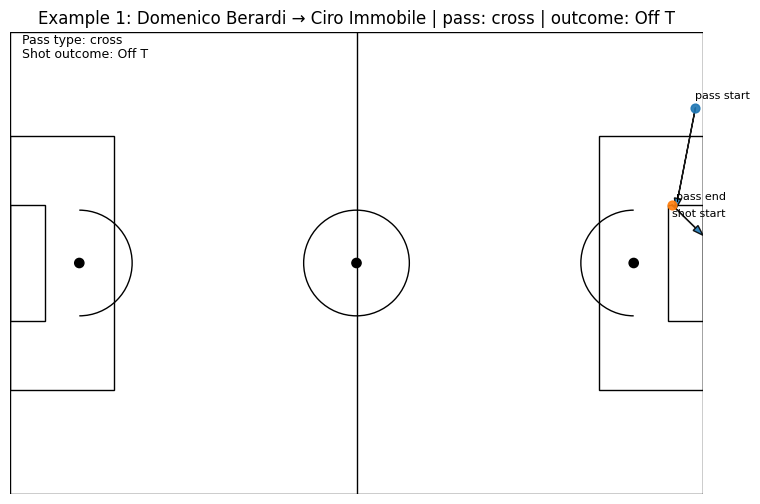

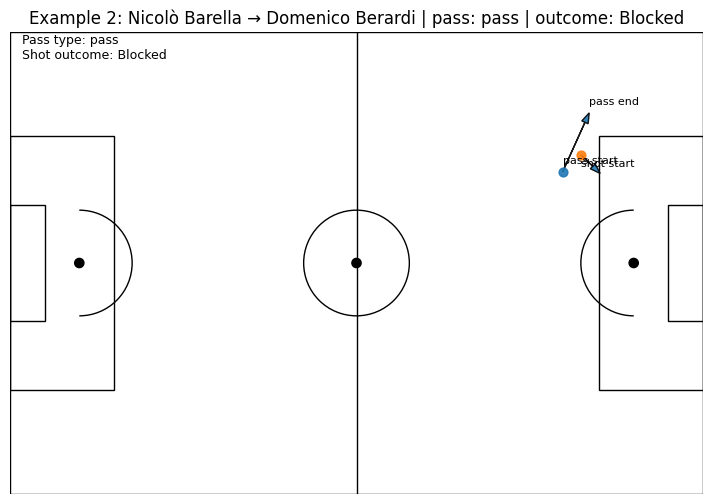

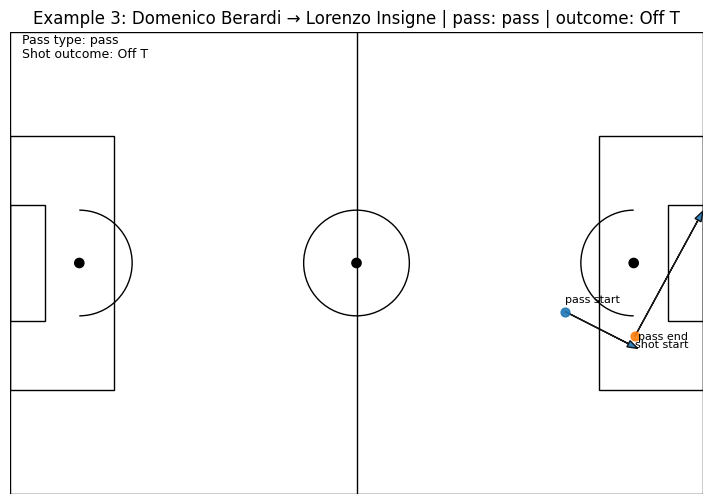

In [38]:
for idx, shot_row in enumerate(pairs, start=1):
    kp = str(shot_row["shot_key_pass_id"]).strip()
    pass_row = events[events["id"].astype(str).str.strip() == kp].iloc[0]

    # Geometry
    p_start = parse_xy(pass_row.get("location"))
    p_end   = parse_xy(pass_row.get("pass_end_location"))
    s_start = parse_xy(shot_row.get("location"))
    s_end   = parse_xy(shot_row.get("shot_end_location"))  # for arrow direction; might be None

    # Labels
    pass_type = infer_pass_type(pass_row) or "pass"
    shot_outcome = safe_val(shot_row, "shot_outcome") or "Shot"
    shooter = safe_val(shot_row, "player")
    passer  = safe_val(pass_row, "player")

    fig, ax = fcp_pitch_120x80()
    title = f"Example {idx}: {passer or 'Player'} → {shooter or 'Shooter'} | pass: {pass_type} | outcome: {shot_outcome}"
    ax.set_title(title)

    # Draw pass (blue)
    if p_start and p_end:
        ax.arrow(p_start[0], p_start[1], p_end[0]-p_start[0], p_end[1]-p_start[1],
                 head_width=1.2, head_length=1.8, length_includes_head=True, alpha=0.9)
        ax.scatter([p_start[0]], [p_start[1]], s=40, alpha=0.9)
        ax.text(p_start[0], p_start[1]+1.5, "pass start", fontsize=8)
        ax.text(p_end[0], p_end[1]+1.5, "pass end", fontsize=8)

    # Draw shot (green)
    if s_start:
        # if no s_end, draw a short marker line
        dx, dy = ( (s_end[0]-s_start[0], s_end[1]-s_start[1]) if s_end else (2.0, 0.0) )
        ax.arrow(s_start[0], s_start[1], dx, dy,
                 head_width=1.2, head_length=1.8, length_includes_head=True, alpha=0.9)
        ax.scatter([s_start[0]], [s_start[1]], s=40, alpha=0.9)
        ax.text(s_start[0], s_start[1]-2.0, "shot start", fontsize=8)

    # Annotations
    if pass_type:
        ax.text(2, 78, f"Pass type: {pass_type}", fontsize=9)
    if shot_outcome:
        ax.text(2, 75.5, f"Shot outcome: {shot_outcome}", fontsize=9)

    plt.show()


In [39]:
# %% [markdown]
# # 2) Shot end location with 3D sense (x, y, z)
# - Plots a simple 3D scatter using shot_end_location’s z (if present).
# - Draws a wireframe for the right-side goal mouth at x=120 (y∈[36,44], z∈[0,~2.7 SB units]).
#   Note: SB units are commonly treated as yards; goal height ≈ 2.44m ≈ 2.67 yards.


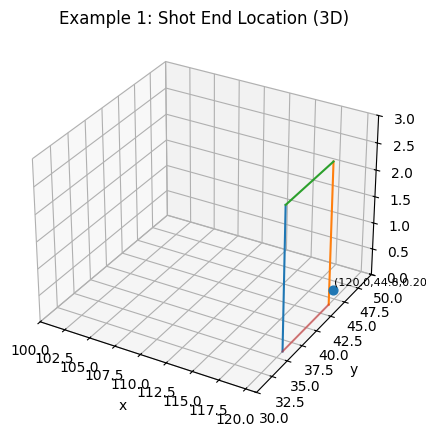

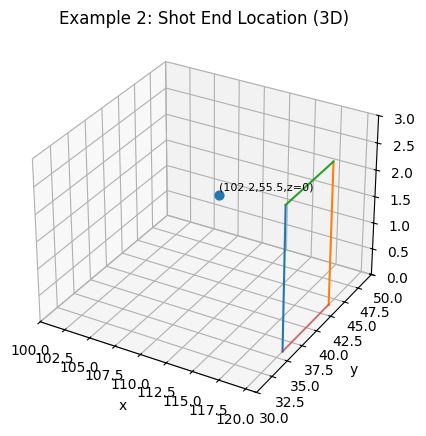

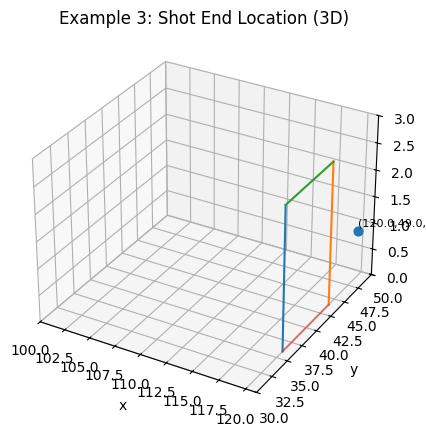

In [40]:
for idx, shot_row in enumerate(pairs, start=1):
    s_xyz = parse_xyz(shot_row.get("shot_end_location"))
    s_xy  = parse_xy(shot_row.get("shot_end_location"))  # if z missing
    if not (s_xyz or s_xy):
        continue

    fig = plt.figure(figsize=(7, 5))
    ax = fig.add_subplot(111, projection='3d')
    ax.set_title(f"Example {idx}: Shot End Location (3D)")

    # Goal mouth at x=120 (wireframe)
    gx = 120.0
    y_posts = [36.0, 44.0]
    z_bar   = 2.67  # ~2.44m -> ~2.67 SB units
    # vertical posts
    ax.plot([gx, gx], [y_posts[0], y_posts[0]], [0, z_bar])
    ax.plot([gx, gx], [y_posts[1], y_posts[1]], [0, z_bar])
    # crossbar
    ax.plot([gx, gx], [y_posts[0], y_posts[1]], [z_bar, z_bar])
    # ground between posts (for reference)
    ax.plot([gx, gx], [y_posts[0], y_posts[1]], [0, 0], alpha=0.5)

    # Plot shot end
    if s_xyz:
        ax.scatter([s_xyz[0]], [s_xyz[1]], [s_xyz[2]], s=40)
        ax.text(s_xyz[0], s_xyz[1], s_xyz[2] + 0.1, f"({s_xyz[0]:.1f},{s_xyz[1]:.1f},{s_xyz[2]:.2f})", fontsize=8)
    else:
        ax.scatter([s_xy[0]], [s_xy[1]], [0.0], s=40)
        ax.text(s_xy[0], s_xy[1], 0.1, f"({s_xy[0]:.1f},{s_xy[1]:.1f},z=0)", fontsize=8)

    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.set_xlim(100, 121); ax.set_ylim(30, 50); ax.set_zlim(0, 3.0)
    plt.show()


In [41]:
# %% [markdown]
# # 3) Shot freeze-frame plot (actor *, teammates o, opponents s)
# - Uses the `shot_freeze_frame` JSON embedded in the shot row (if present).
# - Also overlays pass and shot starts/ends for context.


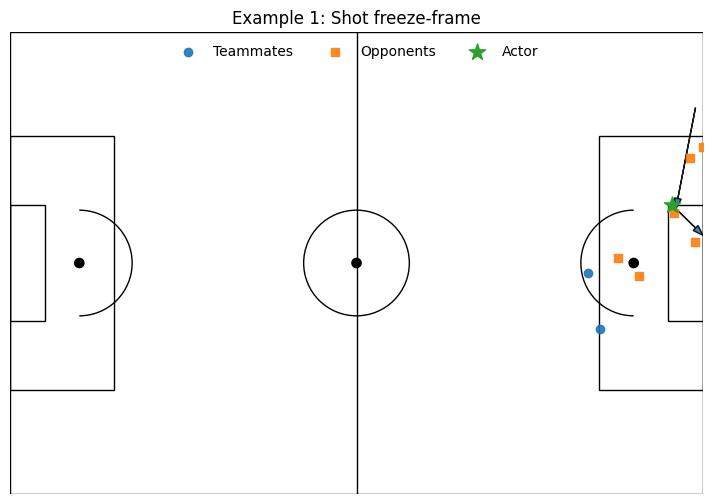

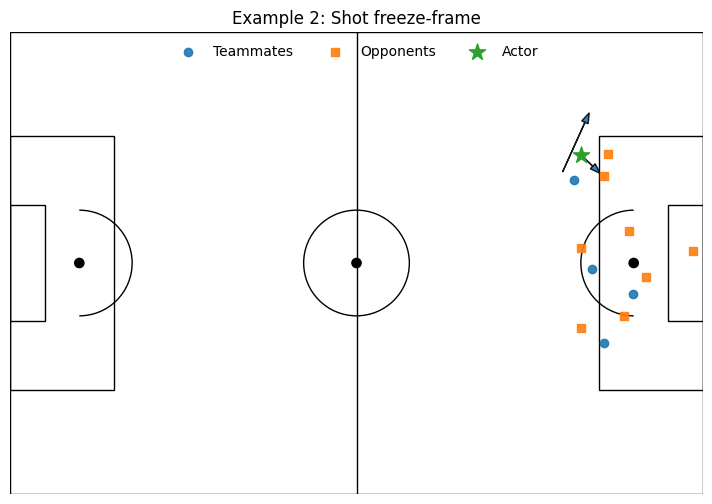

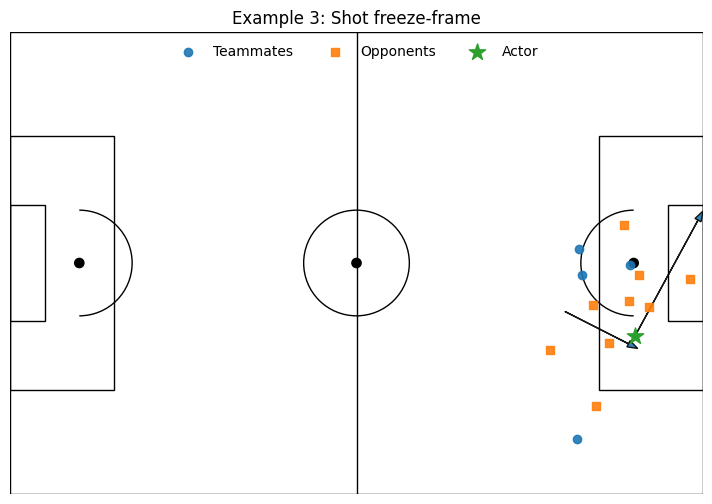

In [42]:
def parse_shot_freeze_frame(val) -> Optional[List[Dict[str, Any]]]:
    if not isinstance(val, str) or not val.strip():
        return None
    try:
        # value is a JSON array of dicts with keys: location, player{id,name}, position, teammate(bool)
        data = json.loads(val)
        if isinstance(data, list):
            return data
    except Exception:
        return None
    return None

for idx, shot_row in enumerate(pairs, start=1):
    ff = parse_shot_freeze_frame(shot_row.get("shot_freeze_frame"))
    if not ff:
        continue

    # Gather pass/shot geometry again
    kp = str(shot_row["shot_key_pass_id"]).strip()
    pass_row = events[events["id"].astype(str).str.strip() == kp].iloc[0]
    p_start = parse_xy(pass_row.get("location"))
    p_end   = parse_xy(pass_row.get("pass_end_location"))
    s_start = parse_xy(shot_row.get("location"))
    s_end   = parse_xy(shot_row.get("shot_end_location"))

    fig, ax = fcp_pitch_120x80()
    ax.set_title(f"Example {idx}: Shot freeze-frame")

    # Draw pass and shot (same styling as before)
    if p_start and p_end:
        ax.arrow(p_start[0], p_start[1], p_end[0]-p_start[0], p_end[1]-p_start[1],
                 head_width=1.2, head_length=1.8, length_includes_head=True, alpha=0.9)
    if s_start:
        dx, dy = ( (s_end[0]-s_start[0], s_end[1]-s_start[1]) if s_end else (2.0, 0.0) )
        ax.arrow(s_start[0], s_start[1], dx, dy,
                 head_width=1.2, head_length=1.8, length_includes_head=True, alpha=0.9)

    # Plot freeze-frame players
    tm_x, tm_y, op_x, op_y, act_x, act_y = [], [], [], [], [], []
    for ent in ff:
        loc = ent.get("location")
        if not isinstance(loc, (list, tuple)) or len(loc) < 2:
            continue
        x, y = float(loc[0]), float(loc[1])
        if ent.get("teammate") is True:
            tm_x.append(x); tm_y.append(y)
        else:
            op_x.append(x); op_y.append(y)

    # Mark actor approximately at shot start location, if available
    if s_start:
        act_x.append(s_start[0]); act_y.append(s_start[1])

    if tm_x:
        ax.scatter(tm_x, tm_y, alpha=0.9, label="Teammates")
    if op_x:
        ax.scatter(op_x, op_y, marker="s", alpha=0.9, label="Opponents")
    if act_x:
        ax.scatter(act_x, act_y, marker="*", s=150, label="Actor", zorder=4)

    ax.legend(loc="upper center", ncol=3, frameon=False)
    plt.show()


# better plots

In [1]:
# %% [markdown]
# # Setup: imports + your pitch helper (Plotly)


In [2]:
import json
import math
from typing import Any, Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import plotly.graph_objects as go

def make_pitch(fig, linecolor="black", lw=2):
    """Add soccer pitch with goal mouths and posts."""
    pitch_shapes = [
        # Outline
        dict(type="rect", x0=0, y0=0, x1=120, y1=80, line=dict(color=linecolor, width=lw)),
        # Halfway line
        dict(type="line", x0=60, y0=0, x1=60, y1=80, line=dict(color=linecolor, width=lw)),
        # Penalty boxes
        dict(type="rect", x0=0, y0=18, x1=18, y1=62, line=dict(color=linecolor, width=lw)),
        dict(type="rect", x0=102, y0=18, x1=120, y1=62, line=dict(color=linecolor, width=lw)),
        # Six-yard boxes
        dict(type="rect", x0=0, y0=30, x1=6, y1=50, line=dict(color=linecolor, width=lw)),
        dict(type="rect", x0=114, y0=30, x1=120, y1=50, line=dict(color=linecolor, width=lw)),
        # Goals (extend beyond pitch)
        dict(type="rect", x0=-2, y0=36, x1=0, y1=44, line=dict(color="black", width=3)),
        dict(type="rect", x0=120, y0=36, x1=122, y1=44, line=dict(color="black", width=3)),
        # Center circle
        dict(type="circle", x0=50, y0=30, x1=70, y1=50, line=dict(color=linecolor, width=lw)),
        # Penalty spots
        dict(type="circle", x0=11, y0=39, x1=13, y1=41, line=dict(color=linecolor, width=lw)),
        dict(type="circle", x0=107, y0=39, x1=109, y1=41, line=dict(color=linecolor, width=lw)),
    ]
    fig.update_layout(
        shapes=pitch_shapes,
        xaxis=dict(range=[0,120], scaleanchor="y", scaleratio=1, visible=False),
        yaxis=dict(range=[0,80], visible=False),
        margin=dict(l=20, r=20, t=60, b=20),
        plot_bgcolor="white",
    )
    return fig


In [3]:
# %% [markdown]
# # Helpers
# - JSON/coordinate parsing
# - pass-type inference (your priority order)
# - example selection (pick 2–3 shots with usable geometry)


In [4]:
def parse_list(val) -> Optional[List[float]]:
    if isinstance(val, (list, tuple)):
        return list(val)
    if isinstance(val, str):
        s = val.strip()
        if not s:
            return None
        try:
            j = json.loads(s.replace("'", '"'))
            if isinstance(j, (list, tuple)):
                return list(j)
        except Exception:
            return None
    return None

def parse_xy(val) -> Optional[Tuple[float, float]]:
    pts = parse_list(val)
    if pts and len(pts) >= 2:
        try:
            return float(pts[0]), float(pts[1])
        except Exception:
            return None
    return None

def parse_xyz(val) -> Optional[Tuple[float, float, float]]:
    pts = parse_list(val)
    if pts and len(pts) >= 3:
        try:
            return float(pts[0]), float(pts[1]), float(pts[2])
        except Exception:
            return None
    return None

PASS_FLAGS_PRIORITY = [
    ("pass_cut_back", "cut back"),
    ("pass_cross", "cross"),
    ("pass_deflected", "deflected"),
    ("pass_inswinging", "inswinging"),
    ("pass_outswinging", "outswinging"),
    ("pass_switch", "switch"),
    ("pass_straight", "straight"),
    ("pass_through_ball", "through ball"),
]

def infer_pass_type(row: pd.Series) -> Optional[str]:
    for col, label in PASS_FLAGS_PRIORITY:
        if col in row.index and pd.notna(row[col]):
            try:
                if bool(row[col]):
                    return label
            except Exception:
                return label
    if "pass_type" in row.index and pd.notna(row["pass_type"]):
        return str(row["pass_type"])
    return None

def choose_examples(events: pd.DataFrame, max_examples: int = 3) -> List[Tuple[pd.Series, pd.Series]]:
    type_col = "type" if "type" in events.columns else ("Type" if "Type" in events.columns else None)
    assert type_col is not None, "No 'type'/'Type' column in events file."
    shots = events[(events[type_col].astype(str).str.lower() == "shot") & events["shot_key_pass_id"].notna()].copy()
    pairs = []
    for _, shot in shots.iterrows():
        kp = str(shot["shot_key_pass_id"]).strip()
        p = events[events["id"].astype(str).str.strip() == kp]
        if p.empty:
            continue
        p = p.iloc[0]
        # need basic geometry
        if parse_xy(p.get("location")) and parse_xy(p.get("pass_end_location")) and parse_xy(shot.get("location")):
            pairs.append((shot, p))
        if len(pairs) >= max_examples:
            break
    return pairs


In [5]:
# %% [markdown]
# # Load one match and pick 2–3 shot→pass examples


In [6]:
EVENTS_CSV = "events_by_match/events_3788741.csv"  # <-- change as needed
events = pd.read_csv(EVENTS_CSV)
examples = choose_examples(events, max_examples=3)
print(f"Examples selected: {len(examples)}")


Examples selected: 3


In [7]:
# %% [markdown]
# # 1) Pass line + Shot line (with pass type & shot outcome)


In [8]:
figs_pass_shot = []
for i, (shot_row, pass_row) in enumerate(examples, start=1):
    p_start = parse_xy(pass_row.get("location"))
    p_end   = parse_xy(pass_row.get("pass_end_location"))
    s_start = parse_xy(shot_row.get("location"))
    s_end   = parse_xy(shot_row.get("shot_end_location"))  # may be None

    # text labels
    passer  = pass_row.get("player", "Passer")
    shooter = shot_row.get("player", "Shooter")
    pass_type = infer_pass_type(pass_row) or "pass"
    shot_outcome = shot_row.get("shot_outcome", "Shot")

    fig = go.Figure()

    # pass: start + end + line
    fig.add_trace(go.Scatter(x=[p_start[0]], y=[p_start[1]], mode="markers",
                             name="pass start", marker=dict(size=8)))
    fig.add_trace(go.Scatter(x=[p_end[0]], y=[p_end[1]], mode="markers",
                             name="pass end", marker=dict(size=8)))
    fig.add_trace(go.Scatter(x=[p_start[0], p_end[0]], y=[p_start[1], p_end[1]],
                             mode="lines", name="pass", line=dict(width=3)))

    # shot: start + (optional) end + line
    fig.add_trace(go.Scatter(x=[s_start[0]], y=[s_start[1]], mode="markers",
                             name="shot start", marker=dict(size=8)))
    if s_end:
        fig.add_trace(go.Scatter(x=[s_end[0]], y=[s_end[1]], mode="markers",
                                 name="shot end", marker=dict(size=8)))
        fig.add_trace(go.Scatter(x=[s_start[0], s_end[0]], y=[s_start[1], s_end[1]],
                                 mode="lines", name="shot", line=dict(width=3)))
    else:
        # short tick in shot direction if no end
        fig.add_trace(go.Scatter(x=[s_start[0], s_start[0]+2], y=[s_start[1], s_start[1]],
                                 mode="lines", name="shot", line=dict(width=3)))

    make_pitch(fig, linecolor="black", lw=2)
    fig.update_layout(
        title=f"Example {i}: {passer} → {shooter} | pass: {pass_type} | outcome: {shot_outcome}",
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="center", x=0.5),
    )
    figs_pass_shot.append(fig)

# To display interactively in a notebook, iterate: for f in figs_pass_shot: f.show()


In [9]:
for f in figs_pass_shot: f.show()

In [10]:
# %% [markdown]
# # 2) Shot end location — 3D


In [14]:
figs_shot3d = []
for i, (shot_row, _) in enumerate(examples, start=1):
    s_xyz = parse_xyz(shot_row.get("shot_end_location"))
    s_xy  = parse_xy(shot_row.get("shot_end_location"))
    if not (s_xyz or s_xy):
        continue

    # goal mouth at x=120
    gx = 120.0
    y0, y1 = 36.0, 44.0
    zbar = 2.67  # ~2.44m in SB units

    # build wireframe segments
    goal_x = [gx, gx, gx]  # reused

    fig3d = go.Figure()

    # posts
    fig3d.add_trace(go.Scatter3d(x=[gx, gx], y=[y0, y0], z=[0, zbar], mode="lines", name="post L"))
    fig3d.add_trace(go.Scatter3d(x=[gx, gx], y=[y1, y1], z=[0, zbar], mode="lines", name="post R"))
    # crossbar
    fig3d.add_trace(go.Scatter3d(x=[gx, gx], y=[y0, y1], z=[zbar, zbar], mode="lines", name="bar"))

    # shot end
    if s_xyz:
        xx, yy, zz = s_xyz
    else:
        xx, yy = s_xy
        zz = 0.0
    fig3d.add_trace(go.Scatter3d(x=[xx], y=[yy], z=[zz], mode="markers+text",
                                 text=[f"({xx:.1f},{yy:.1f},{zz:.2f})"],
                                 textposition="top center",
                                 marker=dict(size=4), name="shot end"))

    fig3d.update_layout(
        title=f"Example {i}: Shot End (3D)",
        scene=dict(
            xaxis_title="x", yaxis_title="y", zaxis_title="z",
            xaxis=dict(range=[100, 121]),
            yaxis=dict(range=[30, 50]),
            zaxis=dict(range=[0, 3.0]),
            aspectmode="cube",
        ),
        margin=dict(l=0, r=0, t=60, b=0),
    )
    figs_shot3d.append(fig3d)

for f in figs_shot3d: f.show()


In [18]:
import plotly.graph_objects as go

def plot_shot_end_3d_true_goal(shot_rows):
    figs = []
    GOAL_WIDTH = 8.0          # y-span (posts at y=36..44)
    GOAL_HEIGHT = 2.67        # z crossbar
    Y_LOW, Y_HIGH = 36.0, 44.0

    for i, shot_row in enumerate(shot_rows, start=1):
        # Prefer [x,y,z]; fall back to [x,y] with z=0
        s_xyz = parse_xyz(shot_row.get("shot_end_location"))
        s_xy  = parse_xy(shot_row.get("shot_end_location"))
        if not (s_xyz or s_xy):
            continue

        if s_xyz:
            sx, sy, sz = s_xyz
        else:
            sx, sy = s_xy
            sz = 0.0

        # Choose goal side: right if shot ends beyond halfway, else left
        right_goal = (sx >= 60.0)

        gx = 120.0 if right_goal else 0.0
        # Tight x-range around the goal plane, ~3 units deep (inside the pitch + beyond the line)
        if right_goal:
            xr = [gx - 3.0, gx + 1.0]
        else:
            xr = [gx - 1.0, gx + 3.0]

        yr = [Y_LOW - 2.0, Y_HIGH + 2.0]          # small padding around posts
        zr = [0.0, GOAL_HEIGHT + 0.4]            # a bit above crossbar for label

        # Build goal mouth wireframe at x=gx
        goal_traces = [
            # Posts
            go.Scatter3d(x=[gx, gx], y=[Y_LOW, Y_LOW], z=[0, GOAL_HEIGHT], mode="lines", name="post L"),
            go.Scatter3d(x=[gx, gx], y=[Y_HIGH, Y_HIGH], z=[0, GOAL_HEIGHT], mode="lines", name="post R"),
            # Crossbar
            go.Scatter3d(x=[gx, gx], y=[Y_LOW, Y_HIGH], z=[GOAL_HEIGHT, GOAL_HEIGHT], mode="lines", name="bar"),
            # Ground between posts
            go.Scatter3d(x=[gx, gx], y=[Y_LOW, Y_HIGH], z=[0, 0], mode="lines", name="goal line"),
        ]

        # Shot end marker
        shot_trace = go.Scatter3d(
            x=[sx], y=[sy], z=[sz],
            mode="markers+text",
            text=[f"({sx:.1f},{sy:.1f},{sz:.2f})"],
            textposition="top center",
            marker=dict(size=4),
            name="shot end",
            showlegend=True,
        )

        fig3d = go.Figure(data=[*goal_traces, shot_trace])

        # Aspect ratio proportional to axis ranges (so units look “true”)
        ar_x = xr[1] - xr[0]
        ar_y = yr[1] - yr[0]
        ar_z = zr[1] - zr[0]

        fig3d.update_layout(
            title=f"Shot End (3D, true goal proportions) — Example {i}",
            scene=dict(
                xaxis_title="x", yaxis_title="y", zaxis_title="z",
                xaxis=dict(range=xr, showgrid=False, zeroline=False),
                yaxis=dict(range=yr, showgrid=False, zeroline=False),
                zaxis=dict(range=zr, showgrid=False, zeroline=False),
                aspectmode="manual",
                aspectratio=dict(x=ar_x, y=ar_y, z=ar_z),
                camera=dict(
                    projection=dict(type="perspective"),
                    eye=dict(x=2.2 if right_goal else -2.2, y=0.0, z=0.9)  # angled view
                ),
            ),
            margin=dict(l=0, r=0, t=60, b=0),
            showlegend=False,
        )
        figs.append(fig3d)
    return figs

# Usage with the examples you selected earlier:
figs_shot3d_true = plot_shot_end_3d_true_goal([s for s, _ in examples])
for f in figs_shot3d_true: f.show()


In [12]:
# %% [markdown]
# # 3) Freeze-frame (shot) + pass/shot overlays


In [16]:
def parse_shot_freeze_frame(val) -> Optional[List[Dict[str, Any]]]:
    if not isinstance(val, str) or not val.strip():
        return None
    try:
        data = json.loads(val)
        return data if isinstance(data, list) else None
    except Exception:
        return None

figs_freeze = []
for i, (shot_row, pass_row) in enumerate(examples, start=1):
    ff = parse_shot_freeze_frame(shot_row.get("shot_freeze_frame"))
    if not ff:
        continue

    # geometry
    p_start = parse_xy(pass_row.get("location"))
    p_end   = parse_xy(pass_row.get("pass_end_location"))
    s_start = parse_xy(shot_row.get("location"))
    s_end   = parse_xy(shot_row.get("shot_end_location"))

    # split teammates/opponents; actor ≈ shot start
    tm_x, tm_y, op_x, op_y = [], [], [], []
    for ent in ff:
        loc = ent.get("location")
        if isinstance(loc, (list, tuple)) and len(loc) >= 2:
            x, y = float(loc[0]), float(loc[1])
            if ent.get("teammate") is True:
                tm_x.append(x); tm_y.append(y)
            else:
                op_x.append(x); op_y.append(y)

    fig = go.Figure()

    # teammates/opponents
    if tm_x:
        fig.add_trace(go.Scatter(x=tm_x, y=tm_y, mode="markers", name="Teammates", marker=dict(size=8)))
    if op_x:
        fig.add_trace(go.Scatter(x=op_x, y=op_y, mode="markers", name="Opponents", marker=dict(size=8, symbol="square")))

    # actor (shot start) if available
    if s_start:
        fig.add_trace(go.Scatter(x=[s_start[0]], y=[s_start[1]], mode="markers", name="Actor (shot)", marker=dict(size=12, symbol="star")))

    # pass/shot overlays (as line traces)
    if p_start and p_end:
        fig.add_trace(go.Scatter(x=[p_start[0], p_end[0]], y=[p_start[1], p_end[1]],
                                 mode="lines+markers", name="Pass", line=dict(width=3)))
    if s_start and s_end:
        fig.add_trace(go.Scatter(x=[s_start[0], s_end[0]], y=[s_start[1], s_end[1]],
                                 mode="lines+markers", name="Shot", line=dict(width=3)))
    elif s_start:
        fig.add_trace(go.Scatter(x=[s_start[0], s_start[0]+2], y=[s_start[1], s_start[1]],
                                 mode="lines+markers", name="Shot", line=dict(width=3)))

    make_pitch(fig, linecolor="black", lw=2)
    fig.update_layout(
        title=f"Example {i}: Shot Freeze-Frame",
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="center", x=0.5),
    )
    figs_freeze.append(fig)

for f in figs_freeze: f.show()


# labels

get all rows where 
- type="Own Goal Against" [its not a shot]
- type="Shot" where shot_statsbomb_xg > 0.27 -> Good chance [get pass details like before]
- type="Shot" where 0.08 < shot_statsbomb_xg <= 0.27 -> Decent chance [get pass details before]
- type="Shot" where shot_outcome="Goal" [get pass details like before] 
- type="Shot" where shot_type="Penalty" and shot_outcome="Goal" or "Saved" (OR corresponding related_events (usually type="Goal Keeper") & goalkeeper_type = "Penalty Saved" or "Goal Conceded" [yet to classify]) [no pass details]
- 

first steps - classify shots into labels (each shot can have multiple labels):
- pass_through_ball [reference like before]
- pass_cross [reference like before]
- pass_cut_back [reference like before]
- Long Shot (>= 22 yards) 
- other. 

every shot must have xg mentioned. 
create a new df


[next steps] - add zones.

In [49]:
# %% [markdown]
# # Shot classification with multi-labels + xG
# Labels per shot:
# - pass_through_ball, pass_cross, pass_cut_back → from the key pass (shot_key_pass_id)
# - Long Shot → distance to nearest goal center ≥ 22 yards (SB units)
# - other → when no label matched above
#
# Output columns (example):
# ['id','match_id','team','player','minute','second','xg','distance_to_goal','labels','shot_key_pass_id']

import json, math
from typing import Optional, Tuple, List
import numpy as np
import pandas as pd

EVENTS_CSV = "events_by_match/events_3788741.csv"  # <-- change as needed
df = pd.read_csv(EVENTS_CSV)

# -------- helpers --------
def parse_xy(val) -> Optional[Tuple[float, float]]:
    """Parse [x,y] stored as list/tuple or JSON-like string."""
    if isinstance(val, (list, tuple)) and len(val) >= 2:
        try:
            return float(val[0]), float(val[1])
        except Exception:
            return None
    if isinstance(val, str):
        s = val.strip()
        if not s:
            return None
        try:
            j = json.loads(s.replace("'", '"'))
            if isinstance(j, (list, tuple)) and len(j) >= 2:
                return float(j[0]), float(j[1])
        except Exception:
            return None
    return None

def dist_to_nearest_goal(xy: Tuple[float, float]) -> float:
    """Euclidean distance from (x,y) to the nearest goal center: left (0,40) or right (120,40)."""
    x, y = xy
    d_left  = math.hypot(x - 0.0,   y - 40.0)
    d_right = math.hypot(x - 120.0, y - 40.0)
    return min(d_left, d_right)

def get_pass_row_by_id(events: pd.DataFrame, pass_id: str) -> Optional[pd.Series]:
    if "id" not in events.columns:
        return None
    m = events[events["id"].astype(str).str.strip() == str(pass_id).strip()]
    return None if m.empty else m.iloc[0]

# columns we will check on the pass row for labels
PASS_FLAG_COLUMNS = ["pass_through_ball", "pass_cross", "pass_cut_back"]

# tolerant 'type' column
type_col = "type" if "type" in df.columns else ("Type" if "Type" in df.columns else None)
assert type_col is not None, "No 'type'/'Type' column in events file."

# -------- build shot table --------
shots = df[df[type_col].astype(str).str.lower() == "shot"].copy()

# get xG column safely
xg_col = "shot_statsbomb_xg" if "shot_statsbomb_xg" in shots.columns else None
if xg_col is None:
    # keep a placeholder column; requirement says "every shot must have xg mentioned"
    shots["xg"] = np.nan
else:
    shots["xg"] = pd.to_numeric(shots[xg_col], errors="coerce")

out_rows = []

for _, r in shots.iterrows():
    labels: List[str] = []

    # 1) pass-based labels from assisting pass (if present)
    kp = r.get("shot_key_pass_id", np.nan)
    if pd.notna(kp):
        prow = get_pass_row_by_id(df, kp)
        if prow is not None:
            for c in PASS_FLAG_COLUMNS:
                if c in prow.index and pd.notna(prow[c]):
                    try:
                        if bool(prow[c]):
                            # map column name -> pretty label
                            if c == "pass_through_ball": labels.append("pass_through_ball")
                            elif c == "pass_cross":      labels.append("pass_cross")
                            elif c == "pass_cut_back":   labels.append("pass_cut_back")
                    except Exception:
                        # any non-null counts as True
                        if c == "pass_through_ball": labels.append("pass_through_ball")
                        elif c == "pass_cross":      labels.append("pass_cross")
                        elif c == "pass_cut_back":   labels.append("pass_cut_back")

    # 2) Long Shot: distance to nearest goal center ≥ 22 (SB units ≈ yards)
    loc = parse_xy(r.get("location"))
    dist_goal = float("nan")
    if loc is not None:
        dist_goal = dist_to_nearest_goal(loc)
        if dist_goal >= 22.0:
            labels.append("Long Shot")

    # 3) other (if nothing else matched)
    if len(labels) == 0:
        labels.append("other")

    out_rows.append({
        "id": r.get("id"),
        "match_id": r.get("match_id"),
        "team": r.get("team"),
        "player": r.get("player"),
        "minute": r.get("minute"),
        "second": r.get("second"),
        "xg": r.get("xg"),
        "distance_to_goal": dist_goal,
        "labels": labels,
        "shot_key_pass_id": r.get("shot_key_pass_id"),
        "shot_outcome": r.get("shot_outcome")
    })

shots_labeled = pd.DataFrame(out_rows)

# Optional: sort by minute/second for readability
with pd.option_context("display.max_columns", 50, "display.width", 180):
    print(shots_labeled.sort_values(["minute","second","id"], na_position="last").to_string(index=False))

# Optional: save
# shots_labeled.to_csv("shots_labeled.csv", index=False)


                                  id  match_id   team              player  minute  second       xg  distance_to_goal              labels                     shot_key_pass_id shot_outcome
fc81639c-6e60-49d3-b29a-82b2b8c5746d   3788741  Italy       Ciro Immobile       2       9 0.052236         11.452947        [pass_cross] 545e570f-ee93-4502-ae49-8bb0ad10b2de        Off T
188ed7fe-c5c0-45f3-9127-e51b05ed8dc9   3788741  Italy    Domenico Berardi      13      25 0.009444         28.193971         [Long Shot] f58e0af9-a687-4552-a6f8-1e44b8f69fed      Blocked
74750b41-c816-4a6c-88d3-b98859039c74   3788741  Italy     Lorenzo Insigne      17       3 0.098552         17.335801             [other] 0f6b342d-4857-44e2-bad2-d967e4f25b5b        Off T
910f8682-7328-436e-aff8-e508c9f6da7a   3788741  Italy    Leonardo Bonucci      19      10 0.006578         35.692576         [Long Shot]                                  NaN        Off T
5fae6701-47c3-4847-b346-5d792c0b94c1   3788741  Italy       Ciro 

# rough checks

In [53]:
events_df = pd.read_csv('events_by_match/events_3788742.csv')

In [43]:
print(events_df[events_df['type']=="Own Goal Against"]['id'])

3801    4a9f326b-e5c1-4d81-bc98-d0992cf85a00
Name: id, dtype: object


In [25]:
events_df['shot_type'].unique()

array([nan, 'Open Play', 'Penalty'], dtype=object)

In [30]:
events_df['goalkeeper_type'].unique()

array([nan, 'Punch', 'Shot Saved', 'Shot Faced', 'Collected',
       'Goal Conceded', 'Penalty Saved'], dtype=object)

In [31]:
events_df['foul_committed_penalty'].unique()

array([nan,  1.])

In [37]:
print(events_df[events_df['foul_committed_penalty']==1]['related_events'][3113])

["49c7ad2b-1c11-4f6c-9f46-c8fe28fe4d79", "cca204a0-f203-41ed-baae-abba36637e5b"]


266b1217-445e-4eb9-ba20-fddd6a352932
""49c7ad2b-1c11-4f6c-9f46-c8fe28fe4d79"", 
""88d7e886-3a40-4803-a9bc-f199c7bc18af"

In [38]:
print(events_df[events_df['foul_committed_penalty']==1]['id'])

3113    88d7e886-3a40-4803-a9bc-f199c7bc18af
Name: id, dtype: object


In [54]:
print(events_df[events_df['shot_type']=="Penalty"]['id'])

3437    922a8677-c805-4e41-98c2-04c075e03851
Name: id, dtype: object


In [40]:
events_df['shot_outcome'].unique()

array([nan, 'Saved', 'Off T', 'Blocked', 'Goal', 'Wayward'], dtype=object)

foul - 88d7e886-3a40-4803-a9bc-f199c7bc18af (foul_committed_pen)
rel - "49c7ad2b-1c11-4f6c-9f46-c8fe28fe4d79" (foul), "cca204a0-f203-41ed-baae-abba36637e5b" (carry)
carry - related - "266b1217-445e-4eb9-ba20-fddd6a352932", "49c7ad2b-1c11-4f6c-9f46-c8fe28fe4d79" (foul), "88d7e886-3a40-4803-a9bc-f199c7bc18af" (foul_committed_pen)

In [34]:
for col in events_df.columns:
    print(col)
    print(events_df[events_df['foul_committed_penalty']==1][col])
    print("\n")

fifty_fifty
3113   NaN
Name: fifty_fifty, dtype: float64


bad_behaviour_card
3113   NaN
Name: bad_behaviour_card, dtype: float64


ball_receipt_outcome
3113    NaN
Name: ball_receipt_outcome, dtype: object


ball_recovery_offensive
3113   NaN
Name: ball_recovery_offensive, dtype: float64


ball_recovery_recovery_failure
3113   NaN
Name: ball_recovery_recovery_failure, dtype: float64


block_deflection
3113   NaN
Name: block_deflection, dtype: float64


block_offensive
3113   NaN
Name: block_offensive, dtype: float64


block_save_block
3113   NaN
Name: block_save_block, dtype: float64


carry_end_location
3113    NaN
Name: carry_end_location, dtype: object


clearance_aerial_won
3113   NaN
Name: clearance_aerial_won, dtype: float64


clearance_body_part
3113    NaN
Name: clearance_body_part, dtype: object


clearance_head
3113   NaN
Name: clearance_head, dtype: float64


clearance_left_foot
3113   NaN
Name: clearance_left_foot, dtype: float64


clearance_other
3113   NaN
Name: clearanc

In [28]:
# Print all values of all columns where df['shot_type']=="Penalty" one by one
for col in events_df.columns:
    print(col)
    print(events_df[events_df['shot_type']=="Penalty"][col])
    print("\n")



# print(events_df[events_df['shot_type']=="Penalty"])

fifty_fifty
3437   NaN
Name: fifty_fifty, dtype: float64


bad_behaviour_card
3437   NaN
Name: bad_behaviour_card, dtype: float64


ball_receipt_outcome
3437    NaN
Name: ball_receipt_outcome, dtype: object


ball_recovery_offensive
3437   NaN
Name: ball_recovery_offensive, dtype: float64


ball_recovery_recovery_failure
3437   NaN
Name: ball_recovery_recovery_failure, dtype: float64


block_deflection
3437   NaN
Name: block_deflection, dtype: float64


block_offensive
3437   NaN
Name: block_offensive, dtype: float64


block_save_block
3437   NaN
Name: block_save_block, dtype: float64


carry_end_location
3437    NaN
Name: carry_end_location, dtype: object


clearance_aerial_won
3437   NaN
Name: clearance_aerial_won, dtype: float64


clearance_body_part
3437    NaN
Name: clearance_body_part, dtype: object


clearance_head
3437   NaN
Name: clearance_head, dtype: float64


clearance_left_foot
3437   NaN
Name: clearance_left_foot, dtype: float64


clearance_other
3437   NaN
Name: clearanc

In [55]:
def important_moments(filename: str):
    """
    Returns a list of key moments (high xG shots, goals, own goals, penalty-winning fouls) for a selected match.
    Fetches events file from S3 if available; falls back to local file for local dev.
    """
    import io
    import pandas as pd
    import numpy as np
    import math
    try:
        df_events = None
        try:
            obj = s3_client.get_object(Bucket=S3_BUCKET, Key=filename)
            df_events = pd.read_csv(io.BytesIO(obj["Body"].read()))
        except Exception as e:
            df_events = pd.read_csv(filename)
        shots = df_events[df_events["type"] == "Shot"].copy()
        if "shot_statsbomb_xg" in shots.columns:
            shots["xg"] = pd.to_numeric(shots["shot_statsbomb_xg"], errors="coerce")
        else:
            shots["xg"] = np.nan
        moments = pd.concat([
            shots[(shots["xg"] >= 0.08) | (shots.get('shot_outcome', '') == "Goal")],
            df_events[df_events['type'] == 'Own Goal Against'],
            df_events[df_events.get('foul_won_penalty', False) == True] if 'foul_won_penalty' in df_events.columns else pd.DataFrame()
        ], ignore_index=True).sort_values(by=['period', 'timestamp'])

        # ===== FILTER: Remove events after 120:00 =====
        if 'minute' in moments.columns and 'second' in moments.columns:
            # Keep events with minute < 120, or minute==120 and second <= 0
            mask = (moments['minute'] < 120) | ((moments['minute'] == 120) & (moments['second'] <= 0))
            moments = moments[mask].copy()

        # Replace all problematic values with None for JSON compatibility
        moments = moments.replace([np.nan, np.inf, -np.inf], None)
        moments = moments.where(pd.notnull(moments), None)
        result = []
        for idx, row in moments.iterrows():
            def safe(val):
                if val is None: return None
                if isinstance(val, float) and (math.isnan(val) or math.isinf(val)): return None
                return val
            player = row.get('player', '')
            if isinstance(player, str) and player.strip():
                parts = player.split()
                who = (f"{parts[0][0]}. {parts[-1]}" if len(parts) >=2 else parts[0])
            else:
                who = "N/A"
            shot_minute = safe(row.get('minute', None))
            shot_second = safe(row.get('second', None))
            if shot_minute is not None and shot_second is not None:
                when = f"{int(shot_minute)}:{int(shot_second):02d}"
            else:
                when = "N/A"
            xg_val = safe(row.get('xg', None))
            xg = round(float(xg_val), 3) if xg_val is not None else None
            event_type = safe(row.get('type', ""))
            outcome = safe(row.get('shot_outcome', None))
            if event_type == "Foul Won" and row.get('foul_won_penalty', False):
                outcome = "Penalty Won"
            possession = safe(row.get('possession'))
            team = safe(row.get('team', None))
            result.append({
                "original_row": int(idx),
                "possession": int(possession) if possession is not None else None,
                "who": who,
                "when": when,
                "event_type": event_type,
                "xg": xg,
                "outcome": outcome,
                "team": team
            })
        # NEW: Group by possession, only keep the last event from each (matches the robust notebook logic)
        if 'possession' in moments.columns:
            moments = moments.sort_values(
                ['possession', 'period', 'minute', 'second', 'timestamp'], 
                ascending=[True, True, True, True, True]
            )
            moments = moments.groupby('possession', as_index=False).last()
        # Remove FULLY duplicate rows after grouping to ensure no duplicate moments are returned
        moments = moments.drop_duplicates()
        return result
    except Exception as e:
        import traceback
        traceback.print_exc()
        from fastapi import HTTPException
        raise HTTPException(status_code=500, detail=f"important_moments failed: {type(e).__name__}: {e}")


important_moments("events_by_match/events_3788741.csv")

/var/folders/np/nf0l0rsx3wn2wmcw1dh1xrhc0000gn/T/ipykernel_99170/3643961460.py:79: PerformanceWarning:

DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`



[{'original_row': 0,
  'possession': 38,
  'who': 'L. Insigne',
  'when': '17:03',
  'event_type': 'Shot',
  'xg': 0.099,
  'outcome': 'Off T',
  'team': 'Italy'},
 {'original_row': 1,
  'possession': 108,
  'who': 'D. Berardi',
  'when': '44:33',
  'event_type': 'Shot',
  'xg': 0.129,
  'outcome': 'Off T',
  'team': 'Italy'},
 {'original_row': 6,
  'possession': 125,
  'who': 'M. Demiral',
  'when': '52:12',
  'event_type': 'Own Goal Against',
  'xg': None,
  'outcome': None,
  'team': 'Turkey'},
 {'original_row': 2,
  'possession': 133,
  'who': 'L. Insigne',
  'when': '56:21',
  'event_type': 'Shot',
  'xg': 0.086,
  'outcome': 'Blocked',
  'team': 'Italy'},
 {'original_row': 3,
  'possession': 145,
  'who': 'C. Immobile',
  'when': '65:33',
  'event_type': 'Shot',
  'xg': 0.354,
  'outcome': 'Goal',
  'team': 'Italy'},
 {'original_row': 4,
  'possession': 162,
  'who': 'L. Insigne',
  'when': '78:30',
  'event_type': 'Shot',
  'xg': 0.192,
  'outcome': 'Goal',
  'team': 'Italy'},
 

# important moments

In [82]:
# %% [markdown]
# # Important moments from a single events CSV (notebook version)
# - Input: path to a StatsBomb events CSV for ONE match.
# - Output:
#     - `moments_df`: tidy DataFrame of important moments
#     - `moments_list`: JSON-safe list of dictionaries (ready for export)
# - Each item includes the ORIGINAL event `id` from the file.

import math
import json
from typing import Tuple, List, Dict, Any, Optional

import numpy as np
import pandas as pd
 

In [83]:
def important_moments_from_file(
    filename: str,
    xg_threshold: float = 0.08,
) -> Tuple[pd.DataFrame, List[Dict[str, Any]]]:
    """
    Returns (moments_df, moments_list) for a match events CSV.
    Each moment includes the original event `id`.

    Moments:
      - Shots with xG >= xg_threshold OR shot_outcome == "Goal"
      - Own Goal Against
      - Foul Won with foul_won_penalty == True  (labeled as 'Penalty Won')

    Post-processing:
      - Filter out events after 120:00 if minute/second exist
      - Sort by period, minute, second, timestamp (when present)
      - If `possession` exists, keep the last event per possession (dedupe)
      - Make values JSON-safe (NaN/inf -> None; numpy scalars -> native)
    """
    df = pd.read_csv(filename)

    # --- Prepare shots & xG ---
    shots = df[df["type"] == "Shot"].copy() if "type" in df.columns else pd.DataFrame()
    if not shots.empty:
        if "shot_statsbomb_xg" in shots.columns:
            shots["xg"] = pd.to_numeric(shots["shot_statsbomb_xg"], errors="coerce")
        else:
            shots["xg"] = np.nan
        shot_mask = (shots["xg"] >= xg_threshold) | (shots.get("shot_outcome", "") == "Goal")
        shots = shots[shot_mask]
    # --- Own goals ---
    own_goals = df[df["type"] == "Own Goal Against"].copy() if "type" in df.columns else pd.DataFrame()
    if not own_goals.empty:
        own_goals["xg"] = np.nan  # no xG for own goals

    # --- Penalty won (foul won with penalty flag) ---
    pen_won = pd.DataFrame()
    if "type" in df.columns and "foul_won_penalty" in df.columns:
        pen_won = df[(df["type"] == "Foul Won") & (df["foul_won_penalty"] == True)].copy()
        if not pen_won.empty:
            pen_won["xg"] = np.nan  # not a shot, but keep xg column for schema consistency

    # --- Combine candidates ---
    moments = pd.concat([shots, own_goals, pen_won], ignore_index=True)

    # Nothing matched
    if moments.empty:
        return moments, []

    # --- Time filter: remove events strictly after 120:00 ---
    if {"minute", "second"}.issubset(moments.columns):
        mask = (moments["minute"] < 120) | ((moments["minute"] == 120) & (moments["second"].fillna(0) <= 0))
        moments = moments[mask].copy()

    # --- Sort by match order ---
    sort_cols = [c for c in ["period", "minute", "second", "timestamp"] if c in moments.columns]
    if sort_cols:
        moments = moments.sort_values(sort_cols, ascending=True, kind="stable")

    # --- Group by possession: keep last in each possession (if possession exists) ---
    if "possession" in moments.columns:
        # Secondary sort to ensure "last()" is deterministic with timestamp when available
        sort_cols2 = [c for c in ["possession", "period", "minute", "second", "timestamp"] if c in moments.columns]
        moments = moments.sort_values(sort_cols2, ascending=True, kind="stable")
        moments = moments.groupby("possession", as_index=False).last()

    # --- Drop exact duplicates if any ---
    moments = moments.drop_duplicates()

    # --- Create a tidy projection with stable columns ---
    def safe(val):
        if val is None:
            return None
        if isinstance(val, float) and (math.isnan(val) or math.isinf(val)):
            return None
        return val

    # Build a clean DataFrame with key fields; keep event `id`
    keep_cols = []
    for c in ["id","match_id","type","team","player","minute","second","timestamp","period","possession","xg","shot_outcome"]:
        if c in moments.columns:
            keep_cols.append(c)

    moments_df = moments[keep_cols].copy()

    # Label "Penalty Won" outcome for the Foul Won + flag case (nice-to-have)
    if {"type", "shot_outcome", "foul_won_penalty"}.issubset(moments.columns):
        mask_pw = (moments["type"] == "Foul Won") & (moments["foul_won_penalty"] == True)
        moments_df.loc[mask_pw.values, "shot_outcome"] = "Penalty Won"

    # JSON-safe list of dicts
    def json_fallback(o):
        if isinstance(o, (np.integer,)):
            return int(o)
        if isinstance(o, (np.floating,)):
            return None if np.isnan(o) else float(o)
        if isinstance(o, (np.bool_,)):
            return bool(o)
        return str(o)

    # Replace NaNs with None for JSON
    moments_df = moments_df.replace([np.nan, np.inf, -np.inf], None)

    moments_list: List[Dict[str, Any]] = []
    for _, row in moments_df.iterrows():
        # Compact "who" label like "C. Immobile"
        who = "N/A"
        player = row.get("player", None)
        if isinstance(player, str) and player.strip():
            parts = player.split()
            who = f"{parts[0][0]}. {parts[-1]}" if len(parts) >= 2 else parts[0]

        # "when" as mm:ss if minute/second present
        m, s = row.get("minute", None), row.get("second", None)
        when = f"{int(m)}:{int(s):02d}" if (m is not None and s is not None) else row.get("timestamp", None) or "N/A"

        item = {
            "event_id": row.get("id"),                           # <-- include original event id
            "match_id": row.get("match_id", None),
            "possession": row.get("possession", None),
            "who": who,
            "when": when,
            "event_type": row.get("type", None),
            "xg": row.get("xg", None),
            "outcome": row.get("shot_outcome", None),
            "team": row.get("team", None),
        }
        # JSON-safe coercion
        for k, v in list(item.items()):
            try:
                item[k] = v if v is None else json.loads(json.dumps(v, default=json_fallback))
            except Exception:
                item[k] = None if v is None else str(v)
        moments_list.append(item)

    return moments_df, moments_list


In [84]:
FILENAME = "events_by_match/events_3788741.csv"  # <-- put your file path here

moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)

# Pretty print the DataFrame
with pd.option_context("display.max_columns", 50, "display.width", 180):
    print(moments_df.to_string(index=False))

# If you want to save:
# moments_df.to_csv("important_moments.csv", index=False)
# with open("important_moments.json", "w", encoding="utf-8") as f:
#     json.dump(moments_list, f, ensure_ascii=False, indent=2)


                                  id  match_id             type   team           player  minute  second    timestamp  period  possession        xg shot_outcome
74750b41-c816-4a6c-88d3-b98859039c74   3788741             Shot  Italy  Lorenzo Insigne      17       3 00:17:03.251       1          38  0.098552        Off T
c07133d1-fa88-45f8-8a40-7be381ddffd1   3788741             Shot  Italy Domenico Berardi      44      33 00:44:33.641       1         108  0.128881        Off T
4a9f326b-e5c1-4d81-bc98-d0992cf85a00   3788741 Own Goal Against Turkey    Merih Demiral      52      12 00:07:12.643       2         125      None         None
c12c958c-b795-4471-b81c-c16582d8205a   3788741             Shot  Italy  Lorenzo Insigne      56      21 00:11:21.502       2         133  0.086273      Blocked
506e2e45-cc7a-4aa8-9c0d-2c8fb339bc2f   3788741             Shot  Italy    Ciro Immobile      65      33 00:20:33.192       2         145  0.353912         Goal
ead96180-5c0c-4ccb-b926-d215ba883fcb   3

## classify shots

In [65]:
# %% [markdown]
# # Classify "Shot" moments with multi-labels + xG
# - Inputs:
#     1) `filename` → path to the full events CSV for the match
#     2) `moments_df` → DataFrame returned by `important_moments_from_file(...)`
# - Output: `shot_moments_labeled` with columns:
#     ['id','match_id','team','player','minute','second','xg','distance_to_goal','labels','labels_str',
#      'shot_key_pass_id','shot_outcome']

import json, math
from typing import Optional, Tuple, List, Dict, Any
import numpy as np
import pandas as pd


In [ ]:
# %% [markdown]
# ## Helpers: coord parsing, distance, and pass lookup


In [66]:
def parse_xy(val) -> Optional[Tuple[float, float]]:
    """Parse [x,y] stored as list/tuple or JSON-like string; None if not parseable."""
    if isinstance(val, (list, tuple)) and len(val) >= 2:
        try:
            return float(val[0]), float(val[1])
        except Exception:
            return None
    if isinstance(val, str):
        s = val.strip()
        if not s:
            return None
        try:
            j = json.loads(s.replace("'", '"'))
            if isinstance(j, (list, tuple)) and len(j) >= 2:
                return float(j[0]), float(j[1])
        except Exception:
            return None
    return None

def dist_to_nearest_goal(xy: Tuple[float, float]) -> float:
    """Euclidean distance from (x,y) to the nearest goal center in SB units (≈ yards)."""
    x, y = xy
    d_left  = math.hypot(x - 0.0,   y - 40.0)
    d_right = math.hypot(x - 120.0, y - 40.0)
    return min(d_left, d_right)

def get_pass_row_by_id(events: pd.DataFrame, pass_id: Any) -> Optional[pd.Series]:
    """Find the pass row by its `id` (string match after strip)."""
    if "id" not in events.columns:
        return None
    m = events[events["id"].astype(str).str.strip() == str(pass_id).strip()]
    return None if m.empty else m.iloc[0]


In [67]:
# %% [markdown]
# ## Core: classify shots from the important moments list


In [68]:
def classify_shot_moments(
    filename: str,
    moments_df: pd.DataFrame,
    long_shot_yards: float = 22.0
) -> pd.DataFrame:
    """
    Classify important moments where type == 'Shot' with multi-labels and xG.

    Labels:
      - From key pass flags (on the pass row referenced by `shot_key_pass_id`):
          pass_through_ball, pass_cross, pass_cut_back
      - 'Long Shot' if distance to nearest goal center >= long_shot_yards
      - 'other' if none matched

    Returns a DataFrame with one row per shot moment.
    """
    # Load full events for lookups (shot_key_pass_id, locations, xg, etc.)
    ev = pd.read_csv(filename)

    # Tolerant type column
    type_col = "type" if "type" in ev.columns else ("Type" if "Type" in ev.columns else None)
    if type_col is None:
        raise ValueError("No 'type'/'Type' column in events CSV.")

    # Shots in the full events (we’ll use this to get fields not present in moments_df)
    ev_shots = ev[ev[type_col].astype(str).str.lower() == "shot"].copy()

    # Ensure an xg column exists on ev_shots
    if "shot_statsbomb_xg" in ev_shots.columns:
        ev_shots["xg"] = pd.to_numeric(ev_shots["shot_statsbomb_xg"], errors="coerce")
    else:
        ev_shots["xg"] = np.nan

    # Focus only on the events that are marked as important moments AND are shots
    if "type" not in moments_df.columns:
        raise ValueError("moments_df must include a 'type' column.")
    shot_ids = set(moments_df.loc[moments_df["type"] == "Shot", "id"]) if "id" in moments_df.columns else set()

    # If moments_df didn't carry 'id', fall back to intersect by time/team (not ideal). We require 'id'.
    if not shot_ids:
        raise ValueError("moments_df must include 'id' for shot events to classify them.")

    shots_focus = ev_shots[ev_shots["id"].isin(shot_ids)].copy()

    # Prepare output rows
    out_rows: List[Dict[str, Any]] = []

    for _, r in shots_focus.iterrows():
        labels: List[str] = []

        # 1) pass-based labels via key pass flags
        kp = r.get("shot_key_pass_id", np.nan)
        if pd.notna(kp):
            prow = get_pass_row_by_id(ev, kp)
            if prow is not None:
                # Only the three you asked for
                if "pass_through_ball" in prow.index and pd.notna(prow["pass_through_ball"]) and bool(prow["pass_through_ball"]):
                    labels.append("pass_through_ball")
                if "pass_cross" in prow.index and pd.notna(prow["pass_cross"]) and bool(prow["pass_cross"]):
                    labels.append("pass_cross")
                if "pass_cut_back" in prow.index and pd.notna(prow["pass_cut_back"]) and bool(prow["pass_cut_back"]):
                    labels.append("pass_cut_back")

        # 2) long shot (>= threshold yards to nearest goal center)
        loc = parse_xy(r.get("location"))
        dist_goal = float("nan")
        if loc is not None:
            dist_goal = dist_to_nearest_goal(loc)
            if dist_goal >= float(long_shot_yards):
                labels.append("Long Shot")

        # 3) other if nothing else matched
        if len(labels) == 0:
            labels.append("other")

        out_rows.append({
            "id": r.get("id"),
            "match_id": r.get("match_id"),
            "team": r.get("team"),
            "player": r.get("player"),
            "minute": r.get("minute"),
            "second": r.get("second"),
            "shot_outcome": r.get("shot_outcome"),
            "xg": r.get("xg"),
            "distance_to_goal": dist_goal,
            "labels": labels,
            "labels_str": ";".join(labels),
            "shot_key_pass_id": r.get("shot_key_pass_id"),
        })

    shot_moments_labeled = pd.DataFrame(out_rows)

    # Keep only the original important shot ids order if you want
    order_ids = moments_df.loc[moments_df["type"] == "Shot", "id"].tolist()
    if "id" in shot_moments_labeled.columns:
        shot_moments_labeled["__order"] = shot_moments_labeled["id"].apply(lambda x: order_ids.index(x) if x in order_ids else 10**9)
        shot_moments_labeled = shot_moments_labeled.sort_values("__order").drop(columns="__order")

    return shot_moments_labeled


In [69]:
# %% [markdown]
# ## Example usage (ties into your earlier function)


In [74]:
FILENAME = "events_by_match/events_3788742.csv"  # <-- your match events CSV

# If you already have moments_df from earlier:
# moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)

shot_moments_labeled = classify_shot_moments(FILENAME, moments_df, long_shot_yards=22.0)

with pd.option_context("display.max_columns", 50, "display.width", 180):
    print(shot_moments_labeled.to_string(index=False))

# Optional save:
# shot_moments_labeled.to_csv("shot_moments_labeled_from_important.csv", index=False)


                                  id  match_id    team                  player  minute  second shot_outcome       xg  distance_to_goal       labels labels_str                     shot_key_pass_id
4e0a9f53-2178-4a45-bd78-4ae93c7cbbe9   3788742 Denmark        Jonas Older Wind      11      22        Off T 0.132159          7.280110 [pass_cross] pass_cross fc8f2e18-47eb-42b0-8644-5f326c89bfb9
78cb3024-7db8-439b-9682-ae9ed18baa7b   3788742 Denmark   Pierre-Emile Højbjerg      14      44        Saved 0.086957         10.700467      [other]      other 44a38ad3-47be-421f-b18e-53764df9ad4d
da5fbab8-0347-4369-9056-df040c778889   3788742 Finland         Joel Pohjanpalo      59       2         Goal 0.288482          6.040695 [pass_cross] pass_cross c6a8b8c1-e63a-47df-bff0-608cfbc649d4
922a8677-c805-4e41-98c2-04c075e03851   3788742 Denmark   Pierre-Emile Højbjerg      73      49        Saved 0.783500         11.900420      [other]      other                                  NaN
80b51d1c-81d8-45da-9

In [73]:
FILENAME = "events_by_match/events_3788742.csv"  # <-- put your file path here

moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)

# Pretty print the DataFrame
with pd.option_context("display.max_columns", 50, "display.width", 180):
    print(moments_df.to_string(index=False))

                                  id  match_id     type    team                  player  minute  second    timestamp  period  possession        xg shot_outcome
4e0a9f53-2178-4a45-bd78-4ae93c7cbbe9   3788742     Shot Denmark        Jonas Older Wind      11      22 00:11:22.430       1          20  0.132159        Off T
78cb3024-7db8-439b-9682-ae9ed18baa7b   3788742     Shot Denmark   Pierre-Emile Højbjerg      14      44 00:14:44.665       1          27  0.086957        Saved
da5fbab8-0347-4369-9056-df040c778889   3788742     Shot Finland         Joel Pohjanpalo      59       2 00:14:02.364       2         120  0.288482         Goal
49c7ad2b-1c11-4f6c-9f46-c8fe28fe4d79   3788742 Foul Won Denmark   Yussuf Yurary Poulsen      72      12 00:27:12.792       2         139      None  Penalty Won
922a8677-c805-4e41-98c2-04c075e03851   3788742     Shot Denmark   Pierre-Emile Højbjerg      73      49 00:28:49.375       2         140    0.7835        Saved
80b51d1c-81d8-45da-94ba-30dbd151ceb8   3

## classify own-goals and penalties

In [75]:
# %% [markdown]
# # Classify Own Goal / Penalty moments by nearest Pass (±5s)
# - For each important moment where:
#     • type == "Own Goal Against", or
#     • type == "Foul Won" AND foul_won_penalty == True
#   find the closest Pass event within ±5 seconds and classify it by pass flags:
#     pass_through_ball, pass_cross, pass_cut_back
#
# - Uses timestamp when available, else falls back to minute/second.
# - Returns a DataFrame with one row per qualifying moment.

import json
import math
from typing import Optional, Tuple, List, Dict, Any
import numpy as np
import pandas as pd


In [76]:
# %% [markdown]
# ## Helpers: time parsing, nearest-pass search, pass-label extraction


In [85]:
def time_to_seconds(row: pd.Series) -> Optional[float]:
    """
    Convert event row time to seconds since kickoff.
    Priority: 'timestamp' -> parse mm:ss(.ms) or hh:mm:ss(.ms)
              else minute/second numeric
    Returns float seconds or None if cannot parse.
    """
    ts = row.get("timestamp", None)
    if isinstance(ts, str) and ts.strip():
        s = ts.strip()
        try:
            parts = s.split(":")
            # support "MM:SS.mmm" or "HH:MM:SS.mmm"
            if len(parts) == 2:  # MM:SS(.ms)
                mm = int(parts[0])
                sec = float(parts[1])
                return mm * 60.0 + sec
            elif len(parts) == 3:  # HH:MM:SS(.ms)
                hh = int(parts[0]); mm = int(parts[1]); sec = float(parts[2])
                return hh * 3600.0 + mm * 60.0 + sec
        except Exception:
            pass
    # fallback to minute/second
    m = row.get("minute", None)
    s = row.get("second", None)
    if pd.notna(m) and pd.notna(s):
        try:
            return float(int(m) * 60 + int(s))
        except Exception:
            return None
    return None

PASS_FLAG_COLUMNS = ["pass_through_ball", "pass_cross", "pass_cut_back"]

def pass_labels_from_row(pass_row: pd.Series) -> List[str]:
    labels: List[str] = []
    for c in PASS_FLAG_COLUMNS:
        if c in pass_row.index and pd.notna(pass_row[c]):
            try:
                if bool(pass_row[c]):
                    labels.append(c)
            except Exception:
                labels.append(c)  # any non-null counts as True
    return labels

def nearest_pass_within(events: pd.DataFrame, center_time: float, window_sec: float = 5.0) -> Optional[pd.Series]:
    """
    Among events with type == 'Pass', find the row whose event time is closest to center_time
    within ±window_sec. Returns the pass row or None.
    """
    if "type" not in events.columns:
        return None
    passes = events[events["type"] == "Pass"].copy()
    if passes.empty:
        return None

    # compute seconds for passes
    passes["_t"] = passes.apply(time_to_seconds, axis=1)
    valid = passes[passes["_t"].notna()].copy()
    if valid.empty:
        return None

    valid["_delta"] = (valid["_t"] - center_time).abs()
    near = valid[valid["_delta"] <= float(window_sec)]
    if near.empty:
        return None

    # choose the closest by absolute delta; tie-breaker = earliest original order
    idx = near["_delta"].idxmin()
    return near.loc[idx]


In [78]:
# %% [markdown]
# ## Core function


In [86]:
def classify_nonshot_moments_by_nearest_pass(
    filename: str,
    moments_df: pd.DataFrame,
    window_sec: float = 5.0
) -> pd.DataFrame:
    """
    For important moments that are non-shots (Own Goal Against, Penalty Won),
    find the closest Pass within ±window_sec and classify by pass flags.

    Returns a DataFrame with columns:
      ['moment_event_id','match_id','type','team','player','minute','second','timestamp',
       'nearest_pass_id','nearest_pass_time_s','delta_seconds',
       'labels','labels_str']
    """
    # load full events to search passes
    ev = pd.read_csv(filename)

    # ensure time columns exist-ish
    ev["_t"] = ev.apply(time_to_seconds, axis=1)

    # filter the moments of interest
    if "type" not in moments_df.columns:
        raise ValueError("moments_df must include a 'type' column.")
    if "id" not in moments_df.columns:
        raise ValueError("moments_df must include the event 'id' column.")

    # own goals
    og_mask = (moments_df["type"] == "Own Goal Against")
    # penalties (Foul Won with penalty flag)
    pen_mask = (moments_df["type"] == "Foul Won")
    if "foul_won_penalty" in moments_df.columns:
        pen_mask = pen_mask & (moments_df["foul_won_penalty"] == True)
    else:
        # If the flag isn't present in moments_df, try to enrich from ev
        if "foul_won_penalty" in ev.columns:
            m_with_flag = moments_df.merge(ev[["id","foul_won_penalty"]], on="id", how="left")
            moments_df = m_with_flag
            pen_mask = (moments_df["type"] == "Foul Won") & (moments_df["foul_won_penalty"] == True)
        else:
            pen_mask = (moments_df["type"] == "Foul Won") & False  # nothing qualifies without the flag

    focus = moments_df[og_mask | pen_mask].copy()
    if focus.empty:
        return pd.DataFrame(columns=[
            "moment_event_id","match_id","type","team","player","minute","second","timestamp",
            "nearest_pass_id","nearest_pass_time_s","delta_seconds","labels","labels_str"
        ])

    rows: List[Dict[str, Any]] = []

    for _, m in focus.iterrows():
        # compute moment time in seconds
        t = time_to_seconds(m)
        if t is None:
            # try to enrich from full events table by id
            ev_row = ev[ev["id"] == m["id"]]
            if not ev_row.empty:
                t = float(ev_row.iloc[0]["_t"]) if pd.notna(ev_row.iloc[0]["_t"]) else None
        nearest = nearest_pass_within(ev, t, window_sec=window_sec) if t is not None else None

        labels: List[str] = []
        nearest_id = None
        nearest_time = None
        delta = None

        if nearest is not None:
            labels = pass_labels_from_row(nearest)
            nearest_id = nearest.get("id")
            nearest_time = nearest.get("_t")
            delta = abs(nearest_time - t) if (nearest_time is not None and t is not None) else None

        # if no pass labels, keep empty list (we don't apply 'Long Shot' to non-shots)
        rows.append({
            "moment_event_id": m.get("id"),
            "match_id": m.get("match_id"),
            "type": m.get("type"),
            "team": m.get("team"),
            "player": m.get("player"),
            "minute": m.get("minute"),
            "second": m.get("second"),
            "timestamp": m.get("timestamp"),
            "nearest_pass_id": nearest_id,
            "nearest_pass_time_s": nearest_time,
            "delta_seconds": delta,
            "labels": labels,
            "labels_str": ";".join(labels) if labels else "",
        })

    out = pd.DataFrame(rows)

    # sort by match order if available
    sort_cols = [c for c in ["minute","second","timestamp"] if c in out.columns]
    if sort_cols:
        out = out.sort_values(sort_cols, ascending=True, kind="stable")

    return out


In [91]:
FILENAME = "events_by_match/events_3788742.csv"  # <-- your match events CSV

# If you already computed `moments_df` using `important_moments_from_file(...)`
# moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)

nonshot_labeled = classify_nonshot_moments_by_nearest_pass(
    filename=FILENAME,
    moments_df=moments_df,
    window_sec=5.0  # ±5 seconds window
)

with pd.option_context("display.max_columns", 80, "display.width", 200):
    print(nonshot_labeled.to_string(index=False))

# Optional: save
# nonshot_labeled.to_csv("nonshot_moments_labeled_by_pass.csv", index=False)


                     moment_event_id  match_id     type    team                player  minute  second    timestamp                      nearest_pass_id  nearest_pass_time_s  delta_seconds labels labels_str
49c7ad2b-1c11-4f6c-9f46-c8fe28fe4d79   3788742 Foul Won Denmark Yussuf Yurary Poulsen      72      12 00:27:12.792 4304f141-04fb-4e9e-af55-b7a004d7c506              1634.94          2.148     []           


In [93]:
import pandas as pd

# Read and filter
df = pd.read_csv('events_by_match/events_3788742.csv')
target_id = '4304f141-04fb-4e9e-af55-b7a004d7c506'  # Replace with your id

# Filter by id and select pass columns
row = df[df['id'] == target_id]
if len(row) == 0:
    print(f"No row found with id = {target_id}")
else:
    pass_cols = [col for col in df.columns if col.startswith('pass')]
    pass_cols.append('timestamp')
    result = row[pass_cols].iloc[0]
    
    print(f"Pass columns for id = {target_id}:\n")
    for col, value in result.items():
        print(f"{col}: {value}")

Pass columns for id = 4304f141-04fb-4e9e-af55-b7a004d7c506:

pass_aerial_won: nan
pass_angle: 0.24175286
pass_assisted_shot_id: nan
pass_body_part: Right Foot
pass_cross: nan
pass_cut_back: nan
pass_deflected: nan
pass_end_location: [76.5, 43.9]
pass_goal_assist: nan
pass_height: High Pass
pass_inswinging: nan
pass_length: 30.074574
pass_miscommunication: nan
pass_no_touch: nan
pass_outcome: Incomplete
pass_outswinging: nan
pass_recipient: Jonas Older Wind
pass_recipient_id: 21261.0
pass_shot_assist: nan
pass_straight: nan
pass_switch: nan
pass_technique: nan
pass_through_ball: nan
pass_type: nan
timestamp: 00:27:14.940


In [90]:
FILENAME = "events_by_match/events_3788742.csv"  # <-- put your file path here

moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)

# Pretty print the DataFrame
with pd.option_context("display.max_columns", 50, "display.width", 180):
    print(moments_df.to_string(index=False))

                                  id  match_id     type    team                  player  minute  second    timestamp  period  possession        xg shot_outcome
4e0a9f53-2178-4a45-bd78-4ae93c7cbbe9   3788742     Shot Denmark        Jonas Older Wind      11      22 00:11:22.430       1          20  0.132159        Off T
78cb3024-7db8-439b-9682-ae9ed18baa7b   3788742     Shot Denmark   Pierre-Emile Højbjerg      14      44 00:14:44.665       1          27  0.086957        Saved
da5fbab8-0347-4369-9056-df040c778889   3788742     Shot Finland         Joel Pohjanpalo      59       2 00:14:02.364       2         120  0.288482         Goal
49c7ad2b-1c11-4f6c-9f46-c8fe28fe4d79   3788742 Foul Won Denmark   Yussuf Yurary Poulsen      72      12 00:27:12.792       2         139      None  Penalty Won
922a8677-c805-4e41-98c2-04c075e03851   3788742     Shot Denmark   Pierre-Emile Højbjerg      73      49 00:28:49.375       2         140    0.7835        Saved
80b51d1c-81d8-45da-94ba-30dbd151ceb8   3

## retry of classifying own goals, pens

In [108]:
# %% [markdown]
# # Classify Own Goal / Penalty moments by nearest *prior* Pass (≤60s)
# Time handling:
# - Prefer absolute `minute` + `second`
# - Else use `period` + `timestamp` (timestamp is since start of period)
# Period offsets (SB): 1=0:00, 2=45:00, 3=90:00, 4=105:00, 5=penalties (ignored)

import json, math
from typing import Optional, Tuple, List, Dict, Any
import numpy as np
import pandas as pd


In [109]:
# %% Helpers: time parsing and pass label extraction
PERIOD_OFFSETS = {1: 0, 2: 45*60, 3: 90*60, 4: 105*60}  # 5 = penalties, usually not timed like play

def parse_ts_seconds(ts: str) -> Optional[float]:
    """Parse 'MM:SS(.ms)' or 'HH:MM:SS(.ms)' → seconds."""
    if not isinstance(ts, str) or not ts.strip():
        return None
    s = ts.strip()
    try:
        parts = s.split(":")
        if len(parts) == 2:
            mm = int(parts[0]); ss = float(parts[1])
            return mm * 60.0 + ss
        elif len(parts) == 3:
            hh = int(parts[0]); mm = int(parts[1]); ss = float(parts[2])
            return hh * 3600.0 + mm * 60.0 + ss
    except Exception:
        return None
    return None

def event_time_seconds(row: pd.Series) -> Optional[float]:
    """
    Absolute match clock in seconds.
    Order:
      1) minute+second (already absolute across match in SB)
      2) period + timestamp (timestamp is per-period; add offset)
    """
    m, s = row.get("minute", None), row.get("second", None)
    if pd.notna(m) and pd.notna(s):
        try:
            return float(int(m) * 60 + int(s))
        except Exception:
            pass

    per = row.get("period", None)
    ts  = row.get("timestamp", None)
    ts_s = parse_ts_seconds(ts) if isinstance(ts, str) else None
    if pd.notna(per) and ts_s is not None:
        per = int(per)
        base = PERIOD_OFFSETS.get(per, 0)
        return base + ts_s

    return None

PASS_FLAG_COLUMNS = ["pass_through_ball", "pass_cross", "pass_cut_back"]

def pass_labels_from_row(pass_row: pd.Series) -> List[str]:
    labs: List[str] = []
    for c in PASS_FLAG_COLUMNS:
        if c in pass_row.index and pd.notna(pass_row[c]):
            try:
                if bool(pass_row[c]):
                    labs.append(c)
            except Exception:
                labs.append(c)
    return labs


In [110]:
# %% Core: nearest prior pass (≤ window_sec) and classification
def classify_nonshot_moments_by_prior_pass(
    filename: str,
    moments_df: pd.DataFrame,
    window_sec: float = 60.0
) -> pd.DataFrame:
    """
    For important moments that are not shots (Own Goal Against, Penalty Won),
    find the closest *prior* Pass within `window_sec` and classify it by pass flags.

    Returns columns:
      ['moment_event_id','match_id','type','team','player','minute','second','timestamp','period',
       'nearest_pass_id','nearest_pass_time_s','delta_seconds','labels','labels_str']
    """
    ev = pd.read_csv(filename)

    # Precompute absolute seconds for all events
    ev["_t"] = ev.apply(event_time_seconds, axis=1)

    # Ensure IDs/types exist
    if "type" not in moments_df.columns or "id" not in moments_df.columns:
        raise ValueError("moments_df must include 'type' and 'id'.")

    # Ensure penalty flag visibility
    if "foul_won_penalty" not in moments_df.columns and "foul_won_penalty" in ev.columns:
        moments_df = moments_df.merge(ev[["id","foul_won_penalty"]], on="id", how="left")

    # Select target moments
    og_mask  = (moments_df["type"] == "Own Goal Against")
    pen_mask = (moments_df["type"] == "Foul Won") & (moments_df.get("foul_won_penalty", False) == True)
    focus = moments_df[og_mask | pen_mask].copy()
    if focus.empty:
        return pd.DataFrame(columns=[
            "moment_event_id","match_id","type","team","player","minute","second","timestamp","period",
            "nearest_pass_id","nearest_pass_time_s","delta_seconds","labels","labels_str"
        ])

    # Pass table with absolute times
    passes = ev[ev["type"] == "Pass"].copy() if "type" in ev.columns else pd.DataFrame()
    if not passes.empty and "_t" not in passes.columns:
        passes["_t"] = passes.apply(event_time_seconds, axis=1)
    passes = passes[passes["_t"].notna()].copy()

    rows: List[Dict[str, Any]] = []

    for _, m in focus.iterrows():
        t = event_time_seconds(m)
        nearest = None
        if t is not None and not passes.empty:
            # only prior passes within window_sec
            cand = passes.copy()
            cand["_delta"] = t - cand["_t"]
            cand = cand[(cand["_delta"] >= 0) & (cand["_delta"] <= float(window_sec))]
            if not cand.empty:
                nearest = cand.loc[cand["_delta"].idxmin()]

        labels = pass_labels_from_row(nearest) if nearest is not None else []
        rows.append({
            "moment_event_id": m.get("id"),
            "match_id": m.get("match_id"),
            "type": m.get("type"),
            "team": m.get("team"),
            "player": m.get("player"),
            "minute": m.get("minute"),
            "second": m.get("second"),
            "timestamp": m.get("timestamp"),
            "period": m.get("period"),
            "nearest_pass_id": (nearest.get("id") if nearest is not None else None),
            "nearest_pass_time_s": (nearest.get("_t") if nearest is not None else None),
            "delta_seconds": (float(nearest["_delta"]) if nearest is not None else None),
            "labels": labels,
            "labels_str": ";".join(labels) if labels else "",
        })

    out = pd.DataFrame(rows)

    # Sort by match order if available
    sort_cols = [c for c in ["period","minute","second","timestamp"] if c in out.columns]
    if sort_cols:
        out = out.sort_values(sort_cols, ascending=True, kind="stable")

    return out


In [125]:
# %% Example usage
FILENAME = "events_by_match/events_3788741.csv"  # <-- your match events CSV

moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)

nonshot_prior_1min = classify_nonshot_moments_by_prior_pass(
    filename=FILENAME,
    moments_df=moments_df,
    window_sec=60.0  # 1 minute prior only
)

with pd.option_context("display.max_columns", 80, "display.width", 200):
    print(nonshot_prior_1min.to_string(index=False))

# Optional: save
# nonshot_prior_1min.to_csv("nonshot_moments_labeled_prior_60s.csv", index=False)


                     moment_event_id  match_id             type   team        player  minute  second    timestamp  period                      nearest_pass_id  nearest_pass_time_s  delta_seconds labels labels_str
4a9f326b-e5c1-4d81-bc98-d0992cf85a00   3788741 Own Goal Against Turkey Merih Demiral      52      12 00:07:12.643       2 136ccb07-c0a1-408d-bf16-e3d8b4c2bcbe               3131.0            1.0     []           


In [126]:
# FILENAME = "events_by_match/events_3788742.csv"  # <-- put your file path here

moments_df, moments_list = important_moments_from_file(FILENAME, xg_threshold=0.08)

# Pretty print the DataFrame
with pd.option_context("display.max_columns", 50, "display.width", 180):
    print(moments_df.to_string(index=False))

                                  id  match_id             type   team           player  minute  second    timestamp  period  possession        xg shot_outcome
74750b41-c816-4a6c-88d3-b98859039c74   3788741             Shot  Italy  Lorenzo Insigne      17       3 00:17:03.251       1          38  0.098552        Off T
c07133d1-fa88-45f8-8a40-7be381ddffd1   3788741             Shot  Italy Domenico Berardi      44      33 00:44:33.641       1         108  0.128881        Off T
4a9f326b-e5c1-4d81-bc98-d0992cf85a00   3788741 Own Goal Against Turkey    Merih Demiral      52      12 00:07:12.643       2         125      None         None
c12c958c-b795-4471-b81c-c16582d8205a   3788741             Shot  Italy  Lorenzo Insigne      56      21 00:11:21.502       2         133  0.086273      Blocked
506e2e45-cc7a-4aa8-9c0d-2c8fb339bc2f   3788741             Shot  Italy    Ciro Immobile      65      33 00:20:33.192       2         145  0.353912         Goal
ead96180-5c0c-4ccb-b926-d215ba883fcb   3

In [116]:
import pandas as pd

# Read and filter
df = pd.read_csv('events_by_match/events_3788743.csv')
target_id = 'c466e853-c733-4d8e-a0d0-31ed08e42c08'  # Replace with your id

# Filter by id and select pass columns
row = df[df['id'] == target_id]
if len(row) == 0:
    print(f"No row found with id = {target_id}")
else:
    pass_cols = [col for col in df.columns if col.startswith('pass')]
    pass_cols.append('timestamp')
    pass_cols.append('minute')
    pass_cols.append('second')

    result = row[pass_cols].iloc[0]
    
    print(f"Pass columns for id = {target_id}:\n")
    for col, value in result.items():
        print(f"{col}: {value}")

Pass columns for id = c466e853-c733-4d8e-a0d0-31ed08e42c08:

pass_aerial_won: nan
pass_angle: 0.066568166
pass_assisted_shot_id: nan
pass_body_part: Left Foot
pass_cross: nan
pass_cut_back: nan
pass_deflected: nan
pass_end_location: [116.2, 28.7]
pass_goal_assist: nan
pass_height: Ground Pass
pass_inswinging: nan
pass_length: 18.039955
pass_miscommunication: nan
pass_no_touch: nan
pass_outcome: nan
pass_outswinging: nan
pass_recipient: Yussuf Yurary Poulsen
pass_recipient_id: 5536.0
pass_shot_assist: nan
pass_straight: nan
pass_switch: nan
pass_technique: nan
pass_through_ball: nan
pass_type: nan
timestamp: 00:27:10.575
minute: 72
second: 10


# sort according to time

In [1]:
import pandas as pd
# %% Sort event data by timestamp (considering period)
def parse_timestamp_to_seconds(timestamp_str: str) -> float:
    """
    Parse timestamp string to seconds.
    
    Formats:
    - "MM:SS" or "MM:SS.ms" -> minutes * 60 + seconds
    - "HH:MM:SS" or "HH:MM:SS.ms" -> hours * 3600 + minutes * 60 + seconds
    
    Args:
        timestamp_str: Timestamp string (e.g., "00:14:27.168" or "14:27.168")
    
    Returns:
        Seconds as float, or None if invalid
    """
    if pd.isna(timestamp_str) or not isinstance(timestamp_str, str):
        return None
    
    try:
        parts = timestamp_str.strip().split(":")
        if len(parts) == 2:
            # MM:SS format
            minutes = int(parts[0])
            seconds = float(parts[1])
            return minutes * 60.0 + seconds
        elif len(parts) == 3:
            # HH:MM:SS format
            hours = int(parts[0])
            minutes = int(parts[1])
            seconds = float(parts[2])
            return hours * 3600.0 + minutes * 60.0 + seconds
    except (ValueError, AttributeError):
        return None
    
    return None

def get_absolute_match_time(row: pd.Series) -> float:
    """
    Calculate absolute match time in seconds from period and timestamp.
    
    Period offsets:
    - Period 1: 0 seconds (0:00 - 45:00)
    - Period 2: 2700 seconds (45:00 - 90:00)
    - Period 3: 5400 seconds (90:00 - 105:00)
    - Period 4: 6300 seconds (105:00 - 120:00)
    
    Args:
        row: DataFrame row with 'period' and 'timestamp' columns
    
    Returns:
        Absolute match time in seconds, or None if cannot be calculated
    """
    # Prefer minute + second if available (already absolute)
    minute = row.get("minute")
    second = row.get("second")
    if pd.notna(minute) and pd.notna(second):
        try:
            return float(int(minute) * 60 + int(second))
        except (ValueError, TypeError):
            pass
    
    # Otherwise use period + timestamp
    period = row.get("period")
    timestamp = row.get("timestamp")
    
    if pd.isna(period):
        return None
    
    # Parse timestamp to seconds
    timestamp_seconds = parse_timestamp_to_seconds(timestamp) if pd.notna(timestamp) else None
    if timestamp_seconds is None:
        return None
    
    # Period offsets (in seconds)
    period_offsets = {
        1: 0,           # 0:00 - 45:00
        2: 45 * 60,     # 45:00 - 90:00
        3: 90 * 60,     # 90:00 - 105:00
        4: 105 * 60,    # 105:00 - 120:00
        5: None         # Penalties (ignore or handle separately)
    }
    
    period = int(period)
    if period in period_offsets:
        offset = period_offsets[period]
        if offset is not None:
            return offset + timestamp_seconds
    
    return None

# %% Fixed sort_events_by_time function
def sort_events_by_time(df: pd.DataFrame) -> pd.DataFrame:
    """
    Sort events DataFrame by absolute match time.
    
    Args:
        df: Events DataFrame with 'period' and 'timestamp' (or 'minute'/'second') columns
    
    Returns:
        Sorted DataFrame
    """
    df_sorted = df.copy()
    
    # Calculate absolute match time for each row
    df_sorted["_absolute_time"] = df_sorted.apply(get_absolute_match_time, axis=1)
    
    # Sort by absolute time (use stable sort to maintain order for ties)
    df_sorted = df_sorted.sort_values(
        "_absolute_time",
        ascending=True,
        na_position="last",
        kind="stable"
    )
    
    # Drop the temporary column
    df_sorted = df_sorted.drop(columns=["_absolute_time"])
    
    # Reset index to maintain clean sequential index
    df_sorted = df_sorted.reset_index(drop=True)
    
    return df_sorted

# Example usage
FILENAME = "events_by_match/events_3788741.csv"
df = pd.read_csv(FILENAME)

print(f"Original DataFrame shape: {df.shape}")
print(f"\nFirst 5 rows (before sorting):")
print(df[['period', 'timestamp', 'minute', 'second', 'type']].head())

# Sort by time
df_sorted = sort_events_by_time(df)

print(f"\nFirst 5 rows (after sorting):")
print(df_sorted[['period', 'timestamp', 'minute', 'second', 'type']].head())

print(f"\nLast 5 rows (after sorting):")
print(df_sorted[['period', 'timestamp', 'minute', 'second', 'type']].tail())

df_sorted.to_csv("sorted_events.csv", index=False)

Original DataFrame shape: (3803, 115)

First 5 rows (before sorting):
   period     timestamp  minute  second         type
0       1  00:00:00.000       0       0  Starting XI
1       1  00:00:00.000       0       0  Starting XI
2       1  00:00:00.000       0       0   Half Start
3       1  00:00:00.000       0       0   Half Start
4       2  00:00:00.000      45       0   Half Start

First 5 rows (after sorting):
   period     timestamp  minute  second         type
0       1  00:00:00.000       0       0  Starting XI
1       1  00:00:00.000       0       0  Starting XI
2       1  00:00:00.000       0       0   Half Start
3       1  00:00:00.000       0       0   Half Start
4       1  00:00:00.878       0       0         Pass

Last 5 rows (after sorting):
      period     timestamp  minute  second           type
3798       2  00:47:59.946      92      59           Duel
3799       2  00:48:02.307      93       2           Pass
3800       2  00:48:03.129      93       3  Ball Receipt*
3

In [6]:
# %% Print events prior to each Shot
FILENAME = "events_by_match/events_3788741.csv"

# Load and sort events
df = pd.read_csv(FILENAME)
df_sorted = sort_events_by_time(df)

# Calculate absolute time for each event (needed for comparison)
df_sorted["_absolute_time"] = df_sorted.apply(get_absolute_match_time, axis=1)

# Find all shots
shots = df_sorted[df_sorted["type"] == "Shot"].copy()

print(f"Total shots found: {len(shots)}")
print("="*100)

# For each shot, find and print events prior to it
for shot_num, (idx, shot_row) in enumerate(shots.iterrows(), 1):
    shot_time = shot_row["_absolute_time"]
    shot_id = shot_row.get("id")
    shot_minute = shot_row.get("minute")
    shot_second = shot_row.get("second")
    shot_player = shot_row.get("player")
    
    # Find events that occurred before this shot
    prior_events = df_sorted[
        (df_sorted["_absolute_time"] < shot_time) & 
        (df_sorted["_absolute_time"].notna())
    ].copy()
    
    print(f"\n{'='*100}")
    print(f"SHOT #{shot_num}")
    print(f"Shot ID: {shot_id}")
    print(f"Player: {shot_player}")
    print(f"Time: {shot_minute}:{shot_second:02d}" if pd.notna(shot_minute) and pd.notna(shot_second) else f"Time: {shot_row.get('timestamp')}")
    print(f"Absolute Time: {shot_time:.2f} seconds")
    print(f"\nEvents prior to this shot: {len(prior_events)}")
    print("-"*100)
    
    # Show last 5 events before the shot
    events_to_show = 5
    if len(prior_events) > 0:
        last_events = prior_events.tail(events_to_show)
        print(f"\nLast {min(events_to_show, len(prior_events))} events before shot:")
        for _, event_row in last_events.iterrows():
            event_minute = event_row.get("minute")
            event_second = event_row.get("second")
            event_time_str = f"{int(event_minute)}:{int(event_second):02d}" if pd.notna(event_minute) and pd.notna(event_second) else event_row.get("timestamp", "N/A")
            print(f"  [{event_time_str}] {event_row.get('type')} - {event_row.get('player', 'N/A')} - {event_row.get('team', 'N/A')}")
    else:
        print("  No events found before this shot")
    
    # Show all event types before shot
    if len(prior_events) > 0:
        event_types = prior_events["type"].value_counts()
        print(f"\nEvent type breakdown (total {len(prior_events)} events):")
        for event_type, count in event_types.head(10).items():
            print(f"  {event_type}: {count}")

# Clean up temporary column
df_sorted = df_sorted.drop(columns=["_absolute_time"])

Total shots found: 27

SHOT #1
Shot ID: fc81639c-6e60-49d3-b29a-82b2b8c5746d
Player: Ciro Immobile
Time: 2:09
Absolute Time: 129.00 seconds

Events prior to this shot: 105
----------------------------------------------------------------------------------------------------

Last 5 events before shot:
  [2:01] Carry - Alessandro Florenzi - Italy
  [2:02] Pass - Alessandro Florenzi - Italy
  [2:07] Pass - Domenico Berardi - Italy
  [2:07] Ball Receipt* - Domenico Berardi - Italy
  [2:08] Pressure - Merih Demiral - Turkey

Event type breakdown (total 105 events):
  Pass: 31
  Ball Receipt*: 31
  Carry: 21
  Pressure: 9
  Miscontrol: 3
  Starting XI: 2
  Half Start: 2
  Duel: 2
  Interception: 1
  Dribble: 1

SHOT #2
Shot ID: 188ed7fe-c5c0-45f3-9127-e51b05ed8dc9
Player: Domenico Berardi
Time: 13:25
Absolute Time: 805.00 seconds

Events prior to this shot: 632
----------------------------------------------------------------------------------------------------

Last 5 events before shot:
  [1

# events prior to important shots

In [9]:
# %% Imports
import math
import json
from typing import Tuple, List, Dict, Any, Optional

import numpy as np
import pandas as pd

In [10]:
# %% Helper: Parse timestamp to seconds
def parse_timestamp_to_seconds(timestamp_str: str) -> float:
    """
    Parse timestamp string to seconds.
    
    Formats:
    - "MM:SS" or "MM:SS.ms" -> minutes * 60 + seconds
    - "HH:MM:SS" or "HH:MM:SS.ms" -> hours * 3600 + minutes * 60 + seconds
    
    Args:
        timestamp_str: Timestamp string (e.g., "00:14:27.168" or "14:27.168")
    
    Returns:
        Seconds as float, or None if invalid
    """
    if pd.isna(timestamp_str) or not isinstance(timestamp_str, str):
        return None
    
    try:
        parts = timestamp_str.strip().split(":")
        if len(parts) == 2:
            # MM:SS format
            minutes = int(parts[0])
            seconds = float(parts[1])
            return minutes * 60.0 + seconds
        elif len(parts) == 3:
            # HH:MM:SS format
            hours = int(parts[0])
            minutes = int(parts[1])
            seconds = float(parts[2])
            return hours * 3600.0 + minutes * 60.0 + seconds
    except (ValueError, AttributeError):
        return None
    
    return None

In [11]:
# %% Helper: Get absolute match time
def get_absolute_match_time(row: pd.Series) -> float:
    """
    Calculate absolute match time in seconds from period and timestamp.
    
    Period offsets:
    - Period 1: 0 seconds (0:00 - 45:00)
    - Period 2: 2700 seconds (45:00 - 90:00)
    - Period 3: 5400 seconds (90:00 - 105:00)
    - Period 4: 6300 seconds (105:00 - 120:00)
    
    Args:
        row: DataFrame row with 'period' and 'timestamp' columns
    
    Returns:
        Absolute match time in seconds, or None if cannot be calculated
    """
    # Prefer minute + second if available (already absolute)
    minute = row.get("minute")
    second = row.get("second")
    if pd.notna(minute) and pd.notna(second):
        try:
            return float(int(minute) * 60 + int(second))
        except (ValueError, TypeError):
            pass
    
    # Otherwise use period + timestamp
    period = row.get("period")
    timestamp = row.get("timestamp")
    
    if pd.isna(period):
        return None
    
    # Parse timestamp to seconds
    timestamp_seconds = parse_timestamp_to_seconds(timestamp) if pd.notna(timestamp) else None
    if timestamp_seconds is None:
        return None
    
    # Period offsets (in seconds)
    period_offsets = {
        1: 0,           # 0:00 - 45:00
        2: 45 * 60,     # 45:00 - 90:00
        3: 90 * 60,     # 90:00 - 105:00
        4: 105 * 60,    # 105:00 - 120:00
        5: None         # Penalties (ignore or handle separately)
    }
    
    period = int(period)
    if period in period_offsets:
        offset = period_offsets[period]
        if offset is not None:
            return offset + timestamp_seconds
    
    return None

In [12]:
# %% Helper: Sort events by time
def sort_events_by_time(df: pd.DataFrame) -> pd.DataFrame:
    """
    Sort events DataFrame by absolute match time.
    
    Args:
        df: Events DataFrame with 'period' and 'timestamp' (or 'minute'/'second') columns
    
    Returns:
        Sorted DataFrame
    """
    df_sorted = df.copy()
    
    # Calculate absolute match time for each row
    df_sorted["_absolute_time"] = df_sorted.apply(get_absolute_match_time, axis=1)
    
    # Sort by absolute time (use stable sort to maintain order for ties)
    df_sorted = df_sorted.sort_values(
        "_absolute_time",
        ascending=True,
        na_position="last",
        kind="stable"
    )
    
    # Drop the temporary column
    df_sorted = df_sorted.drop(columns=["_absolute_time"])
    
    # Reset index to maintain clean sequential index
    df_sorted = df_sorted.reset_index(drop=True)
    
    return df_sorted

In [13]:
# %% Extract Important Moments
def important_moments_from_file(
    filename: str,
    xg_threshold: float = 0.08,
) -> Tuple[pd.DataFrame, List[Dict[str, Any]]]:
    """
    Returns (moments_df, moments_list) for a match events CSV.
    Each moment includes the original event `id`.

    Moments:
      - Shots with xG >= xg_threshold OR shot_outcome == "Goal"
      - Own Goal Against
      - Foul Won with foul_won_penalty == True  (labeled as 'Penalty Won')

    Post-processing:
      - Filter out events after 120:00 if minute/second exist
      - Sort by period, minute, second, timestamp (when present)
      - If `possession` exists, keep the last event per possession (dedupe)
      - Make values JSON-safe (NaN/inf -> None; numpy scalars -> native)
    """
    df = pd.read_csv(filename)

    # --- Prepare shots & xG ---
    shots = df[df["type"] == "Shot"].copy() if "type" in df.columns else pd.DataFrame()
    if not shots.empty:
        if "shot_statsbomb_xg" in shots.columns:
            shots["xg"] = pd.to_numeric(shots["shot_statsbomb_xg"], errors="coerce")
        else:
            shots["xg"] = np.nan
        shot_mask = (shots["xg"] >= xg_threshold) | (shots.get("shot_outcome", "") == "Goal")
        shots = shots[shot_mask]
    # --- Own goals ---
    own_goals = df[df["type"] == "Own Goal Against"].copy() if "type" in df.columns else pd.DataFrame()
    if not own_goals.empty:
        own_goals["xg"] = np.nan  # no xG for own goals

    # --- Penalty won (foul won with penalty flag) ---
    pen_won = pd.DataFrame()
    if "type" in df.columns and "foul_won_penalty" in df.columns:
        pen_won = df[(df["type"] == "Foul Won") & (df["foul_won_penalty"] == True)].copy()
        if not pen_won.empty:
            pen_won["xg"] = np.nan  # not a shot, but keep xg column for schema consistency

    # --- Combine candidates ---
    moments = pd.concat([shots, own_goals, pen_won], ignore_index=True)

    # Nothing matched
    if moments.empty:
        return moments, []

    # --- Time filter: remove events strictly after 120:00 ---
    if {"minute", "second"}.issubset(moments.columns):
        mask = (moments["minute"] < 120) | ((moments["minute"] == 120) & (moments["second"].fillna(0) <= 0))
        moments = moments[mask].copy()

    # --- Sort by match order ---
    sort_cols = [c for c in ["period", "minute", "second", "timestamp"] if c in moments.columns]
    if sort_cols:
        moments = moments.sort_values(sort_cols, ascending=True, kind="stable")

    # --- Group by possession: keep last in each possession (if possession exists) ---
    if "possession" in moments.columns:
        # Secondary sort to ensure "last()" is deterministic with timestamp when available
        sort_cols2 = [c for c in ["possession", "period", "minute", "second", "timestamp"] if c in moments.columns]
        moments = moments.sort_values(sort_cols2, ascending=True, kind="stable")
        moments = moments.groupby("possession", as_index=False).last()

    # --- Drop exact duplicates if any ---
    moments = moments.drop_duplicates()

    # --- Create a tidy projection with stable columns ---
    def safe(val):
        if val is None:
            return None
        if isinstance(val, float) and (math.isnan(val) or math.isinf(val)):
            return None
        return val

    # Build a clean DataFrame with key fields; keep event `id`
    keep_cols = []
    for c in ["id","match_id","type","team","player","minute","second","timestamp","period","possession","xg","shot_outcome"]:
        if c in moments.columns:
            keep_cols.append(c)

    moments_df = moments[keep_cols].copy()

    # Label "Penalty Won" outcome for the Foul Won + flag case (nice-to-have)
    if {"type", "shot_outcome", "foul_won_penalty"}.issubset(moments.columns):
        mask_pw = (moments["type"] == "Foul Won") & (moments["foul_won_penalty"] == True)
        moments_df.loc[mask_pw.values, "shot_outcome"] = "Penalty Won"

    # JSON-safe list of dicts
    def json_fallback(o):
        if isinstance(o, (np.integer,)):
            return int(o)
        if isinstance(o, (np.floating,)):
            return None if np.isnan(o) else float(o)
        if isinstance(o, (np.bool_,)):
            return bool(o)
        return str(o)

    # Replace NaNs with None for JSON
    moments_df = moments_df.replace([np.nan, np.inf, -np.inf], None)

    moments_list: List[Dict[str, Any]] = []
    for _, row in moments_df.iterrows():
        # Compact "who" label like "C. Immobile"
        who = "N/A"
        player = row.get("player", None)
        if isinstance(player, str) and player.strip():
            parts = player.split()
            who = f"{parts[0][0]}. {parts[-1]}" if len(parts) >= 2 else parts[0]

        # "when" as mm:ss if minute/second present
        m, s = row.get("minute", None), row.get("second", None)
        when = f"{int(m)}:{int(s):02d}" if (m is not None and s is not None) else row.get("timestamp", None) or "N/A"

        item = {
            "event_id": row.get("id"),
            "match_id": row.get("match_id", None),
            "possession": row.get("possession", None),
            "who": who,
            "when": when,
            "event_type": row.get("type", None),
            "xg": row.get("xg", None),
            "outcome": row.get("shot_outcome", None),
            "team": row.get("team", None),
        }
        # JSON-safe coercion
        for k, v in list(item.items()):
            try:
                item[k] = v if v is None else json.loads(json.dumps(v, default=json_fallback))
            except Exception:
                item[k] = None if v is None else str(v)
        moments_list.append(item)

    return moments_df, moments_list

In [14]:
# %% Print last 5 events prior to important shots
FILENAME = "events_by_match/events_3788741.csv"

# Step 1: Extract important moments (this filters shots by xG threshold or goals)
print("Extracting important moments...")
moments_df, _ = important_moments_from_file(FILENAME, xg_threshold=0.08)

# Step 2: Get only shots from important moments
important_shots_ids = set(moments_df[moments_df["type"] == "Shot"]["id"].tolist())

print(f"Total important shots: {len(important_shots_ids)}")

# Step 3: Load and sort all events
print("Loading and sorting events...")
df = pd.read_csv(FILENAME)
df_sorted = sort_events_by_time(df)

# Calculate absolute time for each event (needed for comparison)
df_sorted["_absolute_time"] = df_sorted.apply(get_absolute_match_time, axis=1)

# Step 4: Filter to only important shots
important_shots = df_sorted[
    (df_sorted["type"] == "Shot") & 
    (df_sorted["id"].isin(important_shots_ids))
].copy()

print(f"Important shots found in sorted data: {len(important_shots)}")
print("="*100)

# Step 5: For each important shot, find and print last 5 events prior to it
for shot_num, (idx, shot_row) in enumerate(important_shots.iterrows(), 1):
    shot_time = shot_row["_absolute_time"]
    shot_id = shot_row.get("id")
    shot_minute = shot_row.get("minute")
    shot_second = shot_row.get("second")
    shot_player = shot_row.get("player")
    shot_xg = shot_row.get("shot_statsbomb_xg", shot_row.get("xg", "N/A"))
    shot_outcome = shot_row.get("shot_outcome", "N/A")
    
    # Find events that occurred before this shot
    prior_events = df_sorted[
        (df_sorted["_absolute_time"] < shot_time) & 
        (df_sorted["_absolute_time"].notna())
    ].copy()
    
    print(f"\n{'='*100}")
    print(f"IMPORTANT SHOT #{shot_num}")
    print(f"Shot ID: {shot_id}")
    print(f"Player: {shot_player}")
    print(f"Time: {shot_minute}:{shot_second:02d}" if pd.notna(shot_minute) and pd.notna(shot_second) else f"Time: {shot_row.get('timestamp')}")
    print(f"xG: {shot_xg}")
    print(f"Outcome: {shot_outcome}")
    print(f"Absolute Time: {shot_time:.2f} seconds")
    print(f"\nTotal events prior to this shot: {len(prior_events)}")
    print("-"*100)
    
    # Show last 5 events before the shot
    events_to_show = 5
    if len(prior_events) > 0:
        last_events = prior_events.tail(events_to_show)
        print(f"\nLast {min(events_to_show, len(prior_events))} events before shot:")
        for _, event_row in last_events.iterrows():
            event_minute = event_row.get("minute")
            event_second = event_row.get("second")
            event_time_str = f"{int(event_minute)}:{int(event_second):02d}" if pd.notna(event_minute) and pd.notna(event_second) else event_row.get("timestamp", "N/A")
            event_type = event_row.get("type", "N/A")
            event_player = event_row.get("player", "N/A")
            event_team = event_row.get("team", "N/A")
            print(f"  [{event_time_str}] {event_type} - {event_player} ({event_team})")
    else:
        print("  No events found before this shot")

# Clean up temporary column
df_sorted = df_sorted.drop(columns=["_absolute_time"])

Extracting important moments...
Total important shots: 6
Loading and sorting events...
Important shots found in sorted data: 6

IMPORTANT SHOT #1
Shot ID: 74750b41-c816-4a6c-88d3-b98859039c74
Player: Lorenzo Insigne
Time: 17:03
xG: 0.0985515
Outcome: Off T
Absolute Time: 1023.00 seconds

Total events prior to this shot: 800
----------------------------------------------------------------------------------------------------

Last 5 events before shot:
  [17:00] Pass - Lorenzo Insigne (Italy)
  [17:00] Pressure - Mehmet Zeki Çelik (Turkey)
  [17:01] Pass - Domenico Berardi (Italy)
  [17:01] Ball Receipt* - Domenico Berardi (Italy)
  [17:01] Pressure - Hakan Çalhanoğlu (Turkey)

IMPORTANT SHOT #2
Shot ID: c07133d1-fa88-45f8-8a40-7be381ddffd1
Player: Domenico Berardi
Time: 44:33
xG: 0.12888117
Outcome: Off T
Absolute Time: 2673.00 seconds

Total events prior to this shot: 1981
----------------------------------------------------------------------------------------------------

Last 5 event